# Telco Customer Churn: Optimization, Explainable AI and Business Proposal

**Course:** Machine Learning — Yachay Tech
**Author:** Kevin Josué Sánchez Salazar

> **Use of Artificial Intelligence.** The code and markdown of this notebook were generated with the assistance of
> Artificial Intelligence, specifically the Claude agent (Claude Code) with the Opus 5.5 model at *High* effort.
> Claude was used as an assistance tool to generate code and to understand concepts, figures and results.
> All business and technical decisions, as well as the full understanding of the work, belong to the student:
> every decision was made entirely by the human student.

| Part | Content |
|---|---|
| 1 | Data preparation and predictive models |
| 2 | Hyperparameter optimization (Grid, Random, TPE) |
| 3 | Multi-objective optimization (NSGA-II) and Pareto front |
| 4 | Final model and test evaluation |
| 5 | Explainable AI: SHAP and LIME |
| 6 | Business view and model export |
| 7 | Conclusions |

### Methodological rules
- The **test set stays isolated** until the final evaluation.
- All preprocessing lives inside `Pipeline` / `ColumnTransformer`.
- All models and optimizers are compared with the same splits and the same CV protocol.
- Predictive importance **does not imply causality**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_PATH = Path("data") / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Part 1. Data preparation and predictive models

### 1.1 Loading the dataset

In [2]:
telco_data = pd.read_csv(DATA_PATH)
print(f"Rows: {telco_data.shape[0]}  |  Columns: {telco_data.shape[1]}")
telco_data.head()

Rows: 7043  |  Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2 Structure and variable types

`info()` shows the type pandas *inferred* when reading the CSV. An unexpected type (for example, a numeric
column read as text) is usually the first sign of an inconsistency.

In [3]:
telco_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
column_summary = pd.DataFrame({
    "dtype": telco_data.dtypes.astype(str),
    "unique_values": telco_data.nunique(),
    "example_values": [telco_data[column].unique()[:4].tolist() for column in telco_data.columns],
})
column_summary

,dtype,unique_values,example_values
customerID,str,7043,"[7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW]"
gender,str,2,"[Female, Male]"
SeniorCitizen,int64,2,"[0, 1]"
Partner,str,2,"[Yes, No]"
Dependents,str,2,"[No, Yes]"
tenure,int64,73,"[1, 34, 2, 45]"
PhoneService,str,2,"[No, Yes]"
MultipleLines,str,3,"[No phone service, No, Yes]"
InternetService,str,3,"[DSL, Fiber optic, No]"
OnlineSecurity,str,3,"[No, Yes, No internet service]"


**Data dictionary** (grouped by role):

| Group | Variables | Meaning |
|---|---|---|
| Identifier | `customerID` | Unique customer code. |
| Target | `Churn` | The customer left the company within the last month (Yes/No). |
| Demographic | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Gender, senior citizen, has a partner, has dependents. |
| Account | `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` | Months as a customer, contract type, paperless billing, payment method, monthly charge and accumulated charge. |
| Phone | `PhoneService`, `MultipleLines` | Has a phone line; has more than one line. |
| Internet | `InternetService` | Connection type: DSL, fiber optic or none. |
| Internet add-ons | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Services contracted on top of the internet connection. |

### 1.3 Distribution of the target variable `Churn`

Before training any model we need to know how balanced the classes are. This defines which metrics make sense:
with imbalanced classes, a model that always predicts "No" can reach a high Accuracy
without detecting a single customer who churns.

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


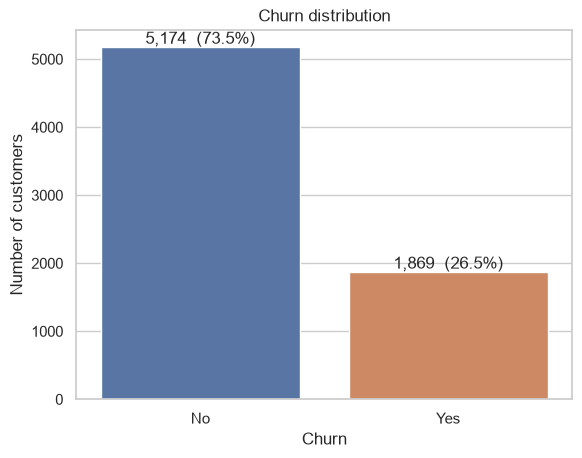

Accuracy of a trivial model that always predicts the majority class: 73.46%


In [5]:
churn_counts = telco_data["Churn"].value_counts()
churn_percentages = telco_data["Churn"].value_counts(normalize=True) * 100
churn_distribution = pd.DataFrame({"customers": churn_counts, "percentage": churn_percentages.round(2)})
display(churn_distribution)

axis = sns.countplot(data=telco_data, x="Churn", hue="Churn", order=["No", "Yes"], legend=False)
for bars in axis.containers:
    axis.bar_label(bars, labels=[f"{count:,.0f}  ({count / len(telco_data):.1%})" for count in bars.datavalues])
axis.set_title("Churn distribution")
axis.set_ylabel("Number of customers")
plt.show()

majority_class_accuracy = churn_percentages.max()
print(f"Accuracy of a trivial model that always predicts the majority class: {majority_class_accuracy:.2f}%")

### 1.4 Missing values and inconsistencies

We check: (a) explicit nulls, (b) values that should be numeric but are not, (c) duplicates,
(d) inconsistent encodings and (e) logical consistency between related columns.

**This section only diagnoses; the treatment is decided afterwards.**

In [6]:
explicit_null_counts = telco_data.isna().sum()
print(f"Explicit nulls in the whole dataset: {explicit_null_counts.sum()}")

Explicit nulls in the whole dataset: 0


#### (b) `TotalCharges` read as text

`TotalCharges` is an amount of money, but pandas read it as text. We try converting it to a number without
modifying the original dataset, to find which values block the conversion.

In [7]:
total_charges_as_number = pd.to_numeric(telco_data["TotalCharges"], errors="coerce")
rows_not_convertible = total_charges_as_number.isna()

print(f"TotalCharges values that cannot be converted to a number: {rows_not_convertible.sum()}")
print("Original values (repr):", telco_data.loc[rows_not_convertible, "TotalCharges"].map(repr).unique().tolist())
telco_data.loc[rows_not_convertible, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

TotalCharges values that cannot be converted to a number: 11
Original values (repr): ["' '"]


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [8]:
customers_with_zero_tenure = (telco_data["tenure"] == 0).sum()
print(f"Customers with tenure = 0: {customers_with_zero_tenure}")
print(f"Are they exactly the same rows that have a blank TotalCharges? "
      f"{(rows_not_convertible == (telco_data['tenure'] == 0)).all()}")

Customers with tenure = 0: 11
Are they exactly the same rows that have a blank TotalCharges? True


#### Consistency between `TotalCharges`, `tenure` and `MonthlyCharges`

If `TotalCharges` is the accumulated charge, it should be close to `tenure × MonthlyCharges`
(not exactly, because the monthly charge may have changed over time).

In [9]:
convertible_rows = ~rows_not_convertible
expected_total_charges = telco_data.loc[convertible_rows, "tenure"] * telco_data.loc[convertible_rows, "MonthlyCharges"]
relative_difference = (total_charges_as_number[convertible_rows] - expected_total_charges) / expected_total_charges

print("Relative difference between TotalCharges and tenure × MonthlyCharges:")
print(relative_difference.describe().round(3))
print(f"Correlation between TotalCharges and tenure × MonthlyCharges: "
      f"{np.corrcoef(total_charges_as_number[convertible_rows], expected_total_charges)[0, 1]:.4f}")

Relative difference between TotalCharges and tenure × MonthlyCharges:
count    7032.000
mean        0.000
std         0.051
min        -0.311
25%        -0.020
50%         0.000
75%         0.020
max         0.573
dtype: float64
Correlation between TotalCharges and tenure × MonthlyCharges: 0.9996


#### (c) Duplicates

In [10]:
print(f"Repeated customerID values: {telco_data['customerID'].duplicated().sum()}")
feature_columns_without_id = telco_data.columns.drop("customerID")
duplicated_profiles = telco_data.duplicated(subset=feature_columns_without_id, keep=False)
print(f"Rows whose full profile (without customerID) appears more than once: {duplicated_profiles.sum()}")
telco_data.loc[duplicated_profiles].sort_values(list(feature_columns_without_id)).head(6)

Repeated customerID values: 0
Rows whose full profile (without customerID) appears more than once: 42


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6491,9728-FTTVZ,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
6764,7660-HDPJV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.2,Yes
4495,4702-IOQDC,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
6267,0328-GRPMV,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.10,70.1,Yes
5522,2619-WFQWU,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes
5759,9985-MWVIX,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,70.15,70.15,Yes


#### (d) Inconsistent encodings

Almost all binary variables use `Yes`/`No`, but it is worth checking that none uses a different format.

In [11]:
binary_columns = [column for column in telco_data.columns if telco_data[column].nunique() == 2]
binary_encodings = pd.Series({column: sorted(telco_data[column].astype(str).unique()) for column in binary_columns})
binary_encodings

gender              [Female, Male]
SeniorCitizen               [0, 1]
Partner                  [No, Yes]
Dependents               [No, Yes]
PhoneService             [No, Yes]
PaperlessBilling         [No, Yes]
Churn                    [No, Yes]
dtype: object

#### (e) Logical consistency: the "No internet service" and "No phone service" categories

The six internet add-on columns have a third category, `No internet service`.
We check that it appears **exactly** when `InternetService == "No"` (and the same for phone service).
If so, that category repeats information already contained in another column.

In [12]:
internet_addon_columns = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                          "TechSupport", "StreamingTV", "StreamingMovies"]
customers_without_internet = telco_data["InternetService"] == "No"

for column in internet_addon_columns:
    matches_internet_service = ((telco_data[column] == "No internet service") == customers_without_internet).all()
    print(f"{column:18s} 'No internet service' matches InternetService == 'No': {matches_internet_service}")

customers_without_phone = telco_data["PhoneService"] == "No"
matches_phone_service = ((telco_data["MultipleLines"] == "No phone service") == customers_without_phone).all()
print(f"{'MultipleLines':18s} 'No phone service' matches PhoneService == 'No':       {matches_phone_service}")

OnlineSecurity     'No internet service' matches InternetService == 'No': True
OnlineBackup       'No internet service' matches InternetService == 'No': True
DeviceProtection   'No internet service' matches InternetService == 'No': True
TechSupport        'No internet service' matches InternetService == 'No': True
StreamingTV        'No internet service' matches InternetService == 'No': True
StreamingMovies    'No internet service' matches InternetService == 'No': True
MultipleLines      'No phone service' matches PhoneService == 'No':       True


#### Audit findings

1. **Class imbalance.** Only 26.54% of customers churn. A trivial model that always predicts "No" already
   reaches 73.46% Accuracy, so Accuracy is not a valid selection metric: we must focus on the churn class
   (Recall, Precision, F1, ROC-AUC) and handle the imbalance during training.
2. **`TotalCharges` is stored as text.** There are no explicit nulls, but 11 values are blank strings. They match
   exactly the 11 customers with `tenure = 0`: new customers who have not been billed yet. The blank is
   therefore not random missing data; it means "no charges so far".
3. **`TotalCharges` is almost redundant.** Its correlation with `tenure × MonthlyCharges` is 0.9996. It carries
   little new information and may cause collinearity in linear models, but it is kept because it reflects
   real accumulated spending.
4. **`customerID` is a pure identifier.** All 7043 values are unique, so it must be excluded from the
   predictors. The 42 rows with repeated profiles have different IDs, so they are treated as distinct customers.
5. **Encoding and redundant categories.** `SeniorCitizen` uses 0/1 while the other binary variables use
   Yes/No. The categories `No internet service` and `No phone service` appear exactly when
   `InternetService == "No"` and `PhoneService == "No"`, so they repeat information from another column.

### 1.5 Data cleaning

Decisions taken after the audit:

| Issue | Decision | Reason |
|---|---|---|
| 11 blank `TotalCharges` values | Fill with **0** | They are exactly the customers with `tenure = 0`: they have not been billed yet. It is a deterministic rule that learns nothing from the data, so applying it before the split causes no leakage. |
| `TotalCharges` vs `tenure × MonthlyCharges` | **Keep** `TotalCharges` | It reflects the real accumulated spending, including price changes over time. |
| 42 rows with repeated profiles | **Keep** them | They have different `customerID` values, so they are most likely distinct customers with the same basic plan. |

In [13]:
telco_clean = telco_data.copy()
telco_clean["TotalCharges"] = pd.to_numeric(telco_clean["TotalCharges"].str.strip().replace("", "0"))

print(f"TotalCharges dtype: {telco_clean['TotalCharges'].dtype}")
print(f"TotalCharges of customers with tenure = 0: {telco_clean.loc[telco_clean['tenure'] == 0, 'TotalCharges'].unique()}")

TotalCharges dtype: float64
TotalCharges of customers with tenure = 0: [0.]


### 1.6 Stratified train/test split

The split is done **before** the bivariate analysis, so that no conclusion drawn from the data
is influenced by the test set.

- `customerID` is removed from the predictors: it is a unique identifier with no predictive information,
  and a model could only use it to memorize customers.
- `Churn` is encoded as `Yes → 1`, `No → 0`, so the positive class is the one we want to detect: the customer who leaves.

In [14]:
features = telco_clean.drop(columns=["customerID", "Churn"])
target = telco_clean["Churn"].map({"Yes": 1, "No": 0})

print(f"Predictors: {features.shape[1]} columns")
print(f"Target distribution: {target.value_counts().to_dict()}")

Predictors: 19 columns
Target distribution: {0: 5174, 1: 1869}


An **80/20 stratified** split is used: stratification keeps the 26.5% churn rate in both sets,
and 20% (≈1400 customers, ≈370 churners) is enough to estimate the final metrics.

In [15]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20
features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=TEST_SIZE, stratify=target, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "customers": [len(target_train), len(target_test)],
    "churners": [target_train.sum(), target_test.sum()],
    "churn_rate_%": [round(target_train.mean() * 100, 2), round(target_test.mean() * 100, 2)],
}, index=["train", "test"])
split_summary

,customers,churners,churn_rate_%
train,5634,1495,26.54
test,1409,374,26.54


### 1.7 Bivariate exploratory analysis (train set only)

*Bivariate* means looking at each predictor **together with** `Churn`, to see whether the churn rate changes
across its values. From here on, only the training set is used.

#### Churn rate by categorical variable

The dashed line is the overall churn rate of the training set. Categories far above it are risk signals.

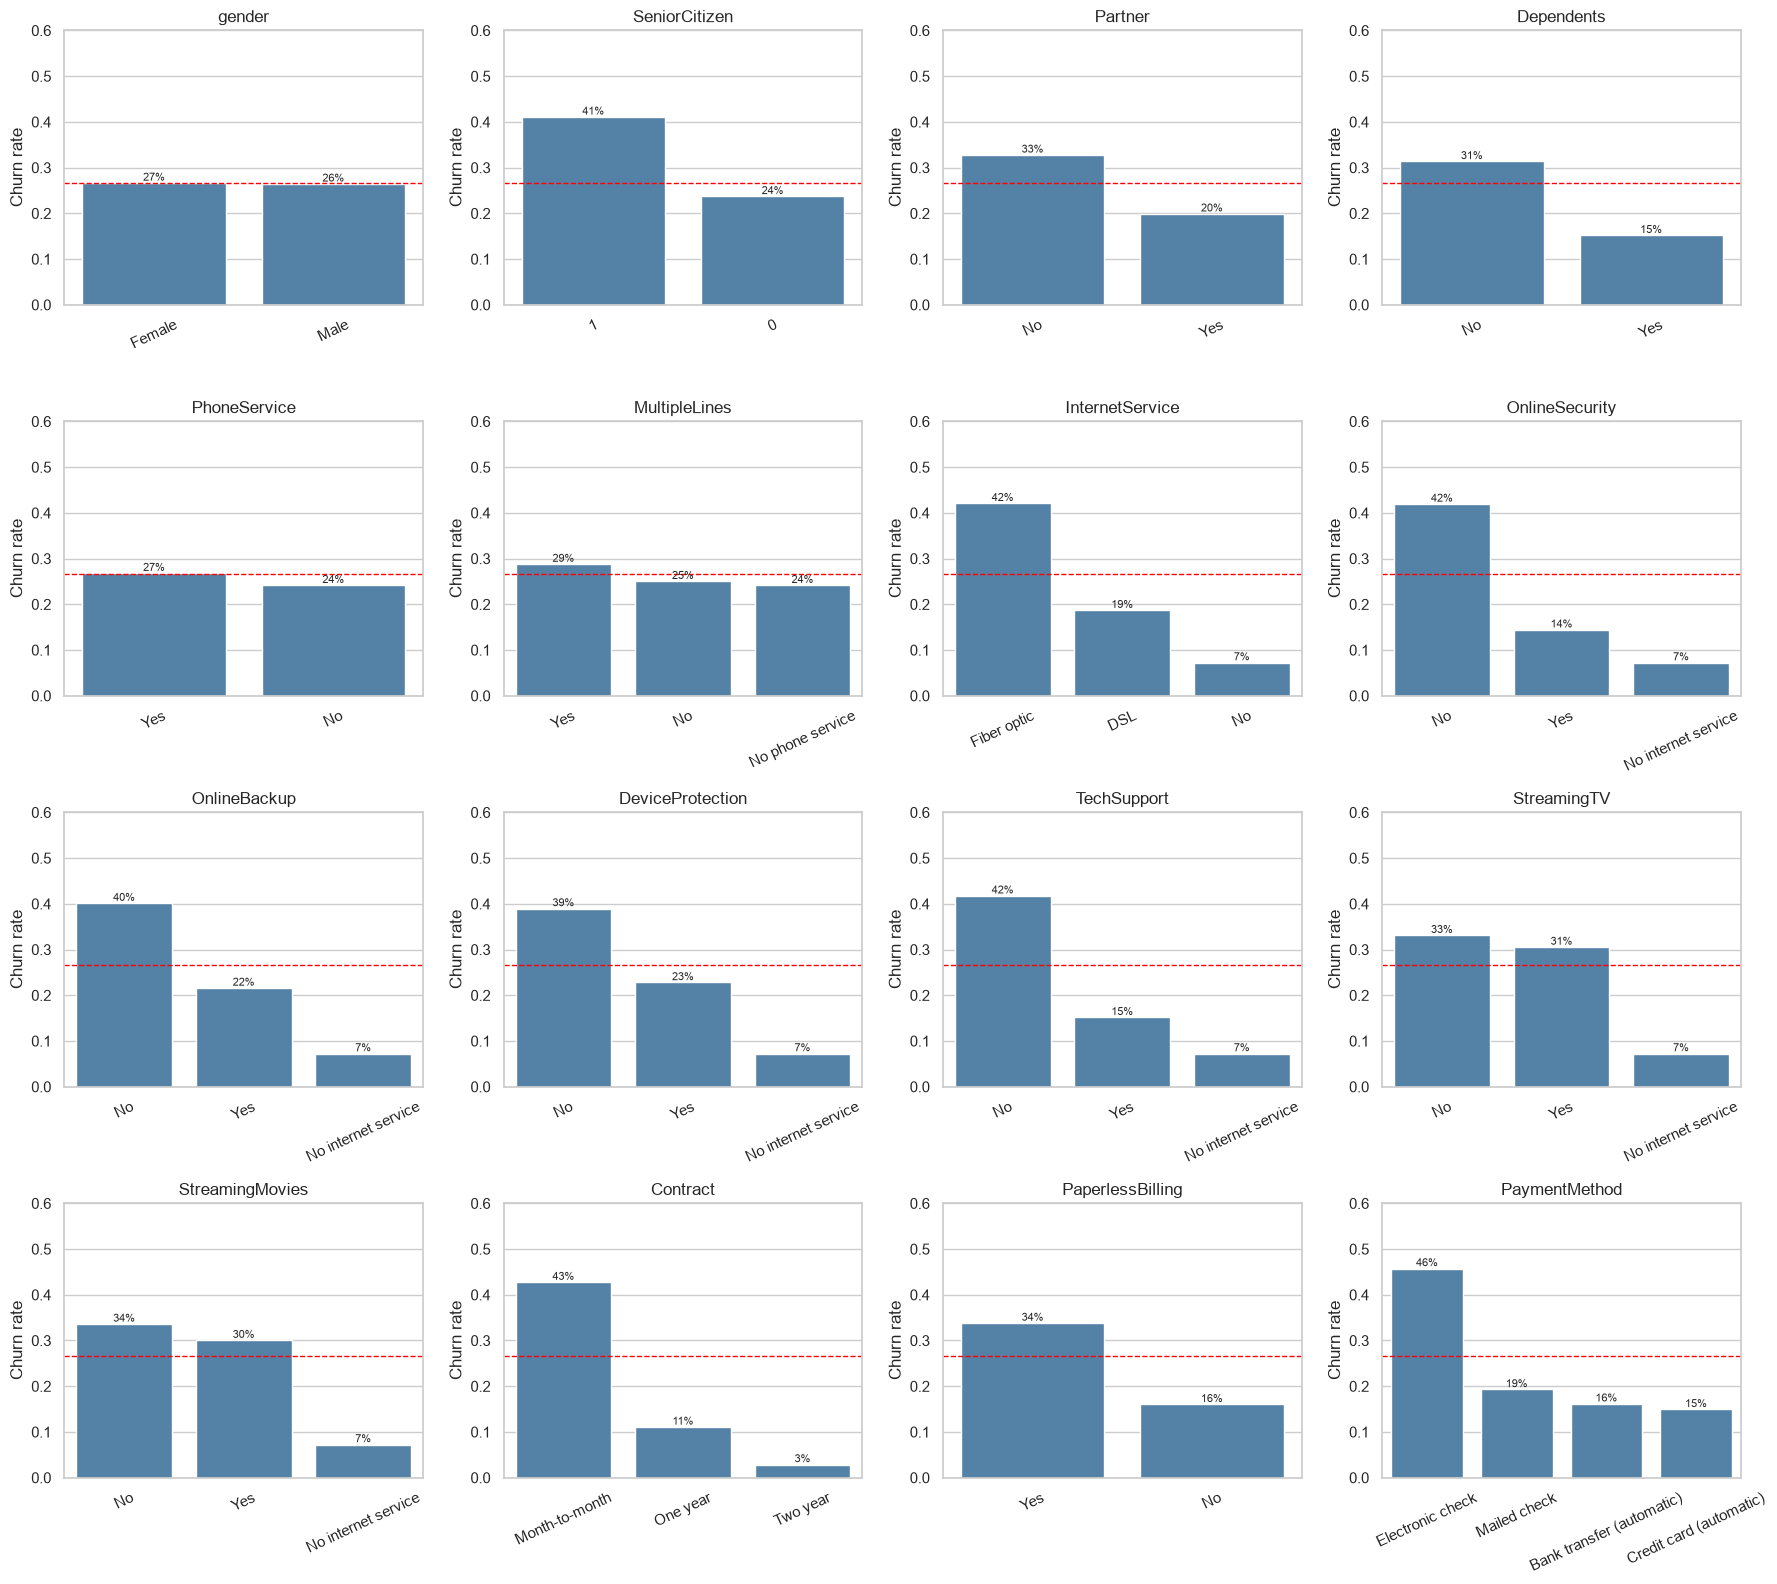

In [16]:
train_data = features_train.assign(Churn=target_train)
overall_churn_rate = target_train.mean()

categorical_columns = [column for column in features_train.columns
                       if features_train[column].dtype == "object" or features_train[column].nunique() <= 4]
figure, axes = plt.subplots(4, 4, figsize=(18, 16))

for axis, column in zip(axes.flat, categorical_columns):
    churn_rate_by_category = train_data.groupby(column)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=churn_rate_by_category.index.astype(str), y=churn_rate_by_category.values, ax=axis, color="steelblue")
    axis.axhline(overall_churn_rate, color="red", linestyle="--", linewidth=1)
    axis.set_title(column)
    axis.set_xlabel("")
    axis.set_ylabel("Churn rate")
    axis.set_ylim(0, 0.6)
    axis.tick_params(axis="x", rotation=25)
    axis.bar_label(axis.containers[0], labels=[f"{rate:.0%}" for rate in churn_rate_by_category.values], fontsize=8)

for unused_axis in axes.flat[len(categorical_columns):]:
    unused_axis.set_visible(False)
plt.tight_layout()
plt.show()

#### Ranking of categories by churn rate

The same information as a table, sorted by the gap between each category's churn rate and the overall rate.

In [17]:
category_churn_rows = []
for column in categorical_columns:
    grouped = train_data.groupby(column)["Churn"].agg(customers="count", churn_rate="mean")
    for category, row in grouped.iterrows():
        category_churn_rows.append({"variable": column, "category": category,
                                    "customers": int(row["customers"]), "churn_rate": row["churn_rate"]})

category_churn_table = pd.DataFrame(category_churn_rows)
category_churn_table["gap_vs_overall"] = category_churn_table["churn_rate"] - overall_churn_rate
category_churn_table.sort_values("gap_vs_overall", ascending=False).head(12).style.format(
    {"churn_rate": "{:.1%}", "gap_vs_overall": "{:+.1%}"})

,variable,category,customers,churn_rate,gap_vs_overall
41,PaymentMethod,Electronic check,1891,45.7%,+19.2%
34,Contract,Month-to-month,3102,42.7%,+16.2%
14,InternetService,Fiber optic,2483,42.1%,+15.6%
16,OnlineSecurity,No,2797,41.9%,+15.4%
25,TechSupport,No,2771,41.8%,+15.2%
3,SeniorCitizen,1,920,41.1%,+14.6%
19,OnlineBackup,No,2442,40.1%,+13.6%
22,DeviceProtection,No,2472,39.0%,+12.4%
38,PaperlessBilling,Yes,3331,33.8%,+7.3%
31,StreamingMovies,No,2217,33.6%,+7.1%


#### Numeric variables vs churn

Distributions of `tenure`, `MonthlyCharges` and `TotalCharges` for customers who stayed (0) and who left (1).

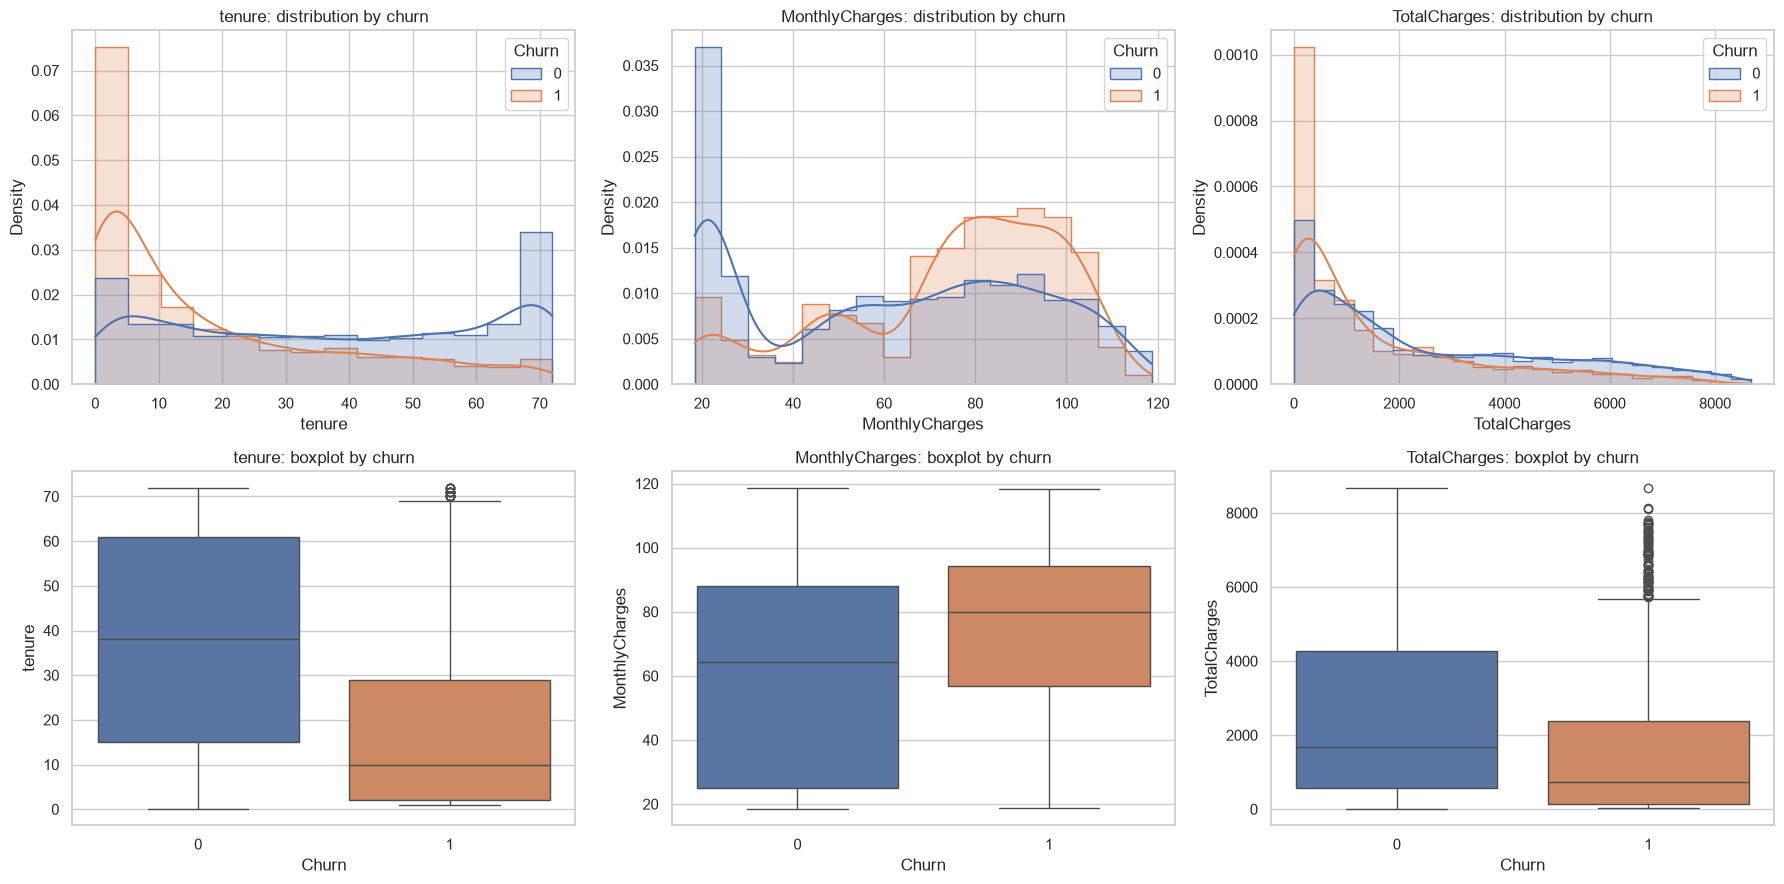

,tenure,MonthlyCharges,TotalCharges
Churn,,,
stayed (median),38.0,64.40,1686.15
left (median),10.0,79.95,740.30


In [18]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
figure, axes = plt.subplots(2, 3, figsize=(18, 9))

for column_index, column in enumerate(numeric_columns):
    sns.histplot(data=train_data, x=column, hue="Churn", stat="density", common_norm=False,
                 kde=True, element="step", ax=axes[0, column_index])
    axes[0, column_index].set_title(f"{column}: distribution by churn")
    sns.boxplot(data=train_data, x="Churn", y=column, hue="Churn", legend=False, ax=axes[1, column_index])
    axes[1, column_index].set_title(f"{column}: boxplot by churn")

plt.tight_layout()
plt.show()

train_data.groupby("Churn")[numeric_columns].median().rename(index={0: "stayed (median)", 1: "left (median)"})

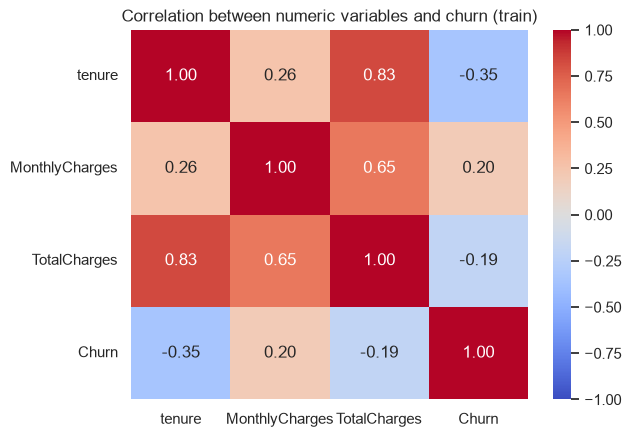

In [19]:
correlation_matrix = train_data[numeric_columns + ["Churn"]].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric variables and churn (train)")
plt.show()

#### Bivariate findings

1. **Commitment is the strongest signal (hypothesis confirmed).** Month-to-month customers churn at 42.7%
   (+16.2 pp over the overall rate), while one-year and two-year contracts churn far less (≈11% and ≈3%).
   Customers without a long-term commitment can leave at no cost.
2. **New customers leave the most.** The median `tenure` is 38 months for customers who stayed and 10 months
   for those who left, and `tenure` has the strongest correlation with churn among numeric variables (−0.35).
   The first months of the relationship are the critical period.
3. **Billing and service profile.** The highest churn rate is `Electronic check` payment (45.7%, +19.2 pp),
   followed by `Fiber optic` internet (42.1%). Fiber customers also pay more: `MonthlyCharges` is higher among
   churners (median 79.95 vs 64.40, correlation +0.20).
4. **Support services are associated with retention.** Customers *without* `OnlineSecurity` (41.9%) or
   `TechSupport` (41.8%) churn far more than average; the same pattern appears for `OnlineBackup` and
   `DeviceProtection`. Senior citizens also churn more (41.1%).
5. **Weak variables.** `gender` shows almost no difference in churn rate between categories, and `PhoneService`
   and `MultipleLines` stay close to the overall rate, so they are expected to add little predictive value.

These are **associations, not causes**: for example, paying by electronic check does not by itself make a
customer leave; it may simply be more common among less committed customers.

#### Business figure B6 — Who leaves?

Figures for a non-technical audience follow three rules: a light background, **one message per chart**,
and a title that states the conclusion instead of describing the axes. They are exported as PNG files to `figures/`
so they can be pasted directly into the presentation.

In [20]:
FIGURES_DIRECTORY = Path("figures")
FIGURES_DIRECTORY.mkdir(exist_ok=True)
BUSINESS_HIGHLIGHT_COLOR = "#d62728"
BUSINESS_NEUTRAL_COLOR = "#b0b7c3"

def save_business_figure(figure, file_name):
    figure.savefig(FIGURES_DIRECTORY / file_name, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

def style_business_axis(axis):
    axis.spines[["top", "right", "left"]].set_visible(False)
    axis.grid(False)
    axis.set_yticks([])

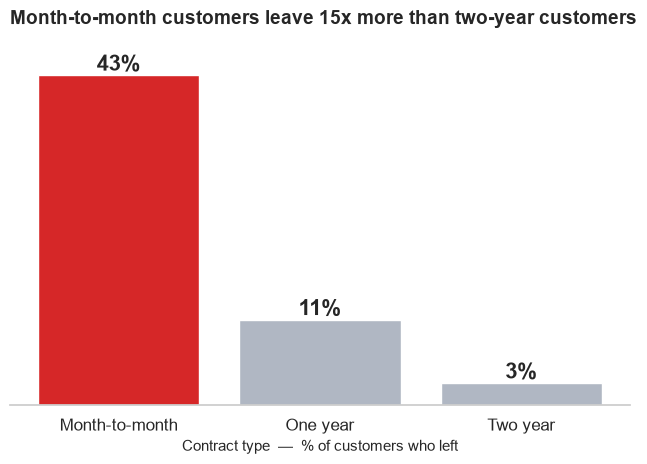

In [21]:
churn_rate_by_contract = train_data.groupby("Contract")["Churn"].mean().reindex(["Month-to-month", "One year", "Two year"])
contract_risk_ratio = churn_rate_by_contract["Month-to-month"] / churn_rate_by_contract["Two year"]

figure, axis = plt.subplots(figsize=(8, 4.5))
bar_colors = [BUSINESS_HIGHLIGHT_COLOR, BUSINESS_NEUTRAL_COLOR, BUSINESS_NEUTRAL_COLOR]
bars = axis.bar(churn_rate_by_contract.index, churn_rate_by_contract.values, color=bar_colors)
axis.bar_label(bars, labels=[f"{rate:.0%}" for rate in churn_rate_by_contract.values], fontsize=16, fontweight="bold")
axis.set_title(f"Month-to-month customers leave {contract_risk_ratio:.0f}x more than two-year customers",
               fontsize=14, fontweight="bold", loc="left", pad=25)
axis.set_xlabel("Contract type  —  % of customers who left", fontsize=11)
axis.tick_params(axis="x", labelsize=12)
style_business_axis(axis)
save_business_figure(figure, "B6a_churn_by_contract.png")

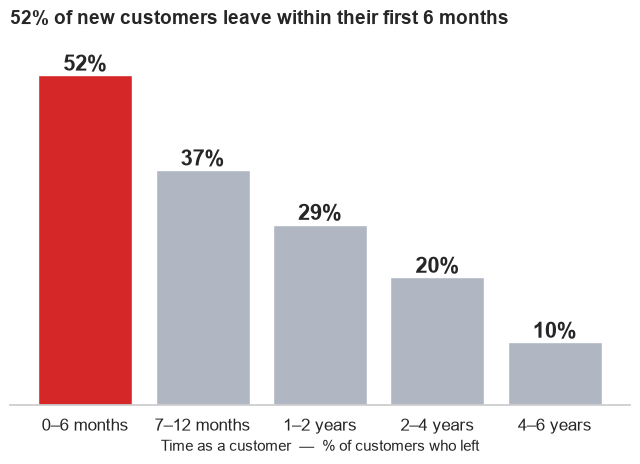

In [22]:
tenure_band_edges = [-1, 6, 12, 24, 48, 72]
tenure_band_labels = ["0–6 months", "7–12 months", "1–2 years", "2–4 years", "4–6 years"]
tenure_bands = pd.cut(train_data["tenure"], bins=tenure_band_edges, labels=tenure_band_labels)
churn_rate_by_tenure_band = train_data.groupby(tenure_bands, observed=True)["Churn"].mean()

figure, axis = plt.subplots(figsize=(8, 4.5))
bar_colors = [BUSINESS_HIGHLIGHT_COLOR] + [BUSINESS_NEUTRAL_COLOR] * (len(churn_rate_by_tenure_band) - 1)
bars = axis.bar(churn_rate_by_tenure_band.index.astype(str), churn_rate_by_tenure_band.values, color=bar_colors)
axis.bar_label(bars, labels=[f"{rate:.0%}" for rate in churn_rate_by_tenure_band.values], fontsize=16, fontweight="bold")
axis.set_title(f"{churn_rate_by_tenure_band.iloc[0]:.0%} of new customers leave within their first 6 months",
               fontsize=14, fontweight="bold", loc="left", pad=25)
axis.set_xlabel("Time as a customer  —  % of customers who left", fontsize=11)
axis.tick_params(axis="x", labelsize=12)
style_business_axis(axis)
save_business_figure(figure, "B6b_churn_by_tenure.png")

### 1.8 Preprocessing with `ColumnTransformer` and `Pipeline`

| Column group | Transformation | Reason |
|---|---|---|
| Numeric (`tenure`, `MonthlyCharges`, `TotalCharges`) | `StandardScaler` | Logistic Regression is sensitive to scale; tree models are not affected. |
| Categorical (all others, including `SeniorCitizen`) | `OneHotEncoder(drop="if_binary", handle_unknown="ignore")` | One column per category; binary variables become a single 0/1 column. Unknown categories in production are ignored instead of crashing. |

**Why this prevents data leakage:** the scaler and encoder are *inside* the pipeline, so in every
cross-validation fold they are fitted only on that fold's training part. The validation fold and the test set
never contribute to the means, standard deviations or category lists.

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [column for column in features_train.columns if column not in numeric_features]

def build_preprocessor():
    return ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False),
         categorical_features),
    ])

preprocessed_preview = build_preprocessor().fit(features_train)
print(f"Numeric features: {len(numeric_features)}  |  Categorical features: {len(categorical_features)}")
print(f"Columns after preprocessing: {len(preprocessed_preview.get_feature_names_out())}")

Numeric features: 3  |  Categorical features: 16
Columns after preprocessing: 40


### 1.9 Model comparison with cross-validation

Three model families are compared under **exactly the same protocol**:

| Model | Family | Why it is included |
|---|---|---|
| Logistic Regression | Linear | Simple, fast and interpretable baseline. |
| Random Forest | Bagging of trees | Captures non-linear interactions; its feature importance is compared with SHAP in Part 4. |
| Support Vector Machine (RBF kernel) | Maximum-margin classifier | Finds the boundary with the widest margin between classes; the RBF kernel allows non-linear boundaries. |

- **Class imbalance:** `class_weight="balanced"` gives more weight to errors on the churn class.
- **Validation:** `StratifiedKFold` with 5 folds; the same folds are reused for every model and every optimizer.
- **Primary metric: F2** (churn class), explained below. Accuracy is misleading here (73.46% for a trivial model).

#### Why F2 is the primary metric

Two basic metrics describe how well the churn class is detected:

- **Recall** $= \frac{TP}{TP + FN}$ — *of all the customers who actually leave, how many did the model detect?*
  Low recall means churners walk away without the company even trying to keep them (false negatives).
- **Precision** $= \frac{TP}{TP + FP}$ — *of all the customers the model flags as "will leave", how many really leave?*
  Low precision means many loyal customers are contacted unnecessarily (false positives).

The **F-beta score** combines both into a single number:

$$F_\beta = \frac{(1 + \beta^2) \cdot \text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}$$

- With $\beta = 1$ it is the usual **F1**: precision and recall weigh the same.
- With $\beta = 2$ (**F2**), **recall weighs twice as much as precision**.

Like F1, it is a *harmonic* combination, so it is still penalized when either component is very low:
a model that flags every customer as a churner (recall = 100%, precision ≈ 26.5%) does not get a high F2.

**Business reason for choosing F2.** The two errors do not cost the same for this company:

| Error | Consequence | Cost |
|---|---|---|
| False negative | A churner is missed and leaves without any retention attempt | All future revenue of that customer (real data: `MonthlyCharges` every month) |
| False positive | A loyal customer receives an unnecessary retention contact | One contact (hypothetical ≈ $10) and some annoyance |

Missing a churner is much more expensive than an unnecessary call, so recall must be prioritized.
However, contacting loyal customers too often is also undesirable, so precision cannot be ignored.
F2 expresses exactly this preference, whereas Recall alone would reward flagging everyone.

In [24]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay, make_scorer, fbeta_score

cross_validation_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
f2_scorer = make_scorer(fbeta_score, beta=2)
scoring_metrics = {"f2": f2_scorer, "accuracy": "accuracy", "precision": "precision",
                   "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
PRIMARY_METRIC = "f2"

candidate_models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight="balanced", n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    # ROC-AUC for the SVM is computed from its decision_function (distance to the margin).
    "SVM (RBF)": SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
}

def build_pipeline(model):
    return Pipeline([("preprocessor", build_preprocessor()), ("model", model)])

cross_validation_results = {}
out_of_fold_predictions = {}
for model_name, model in candidate_models.items():
    start_time = time.perf_counter()
    fold_scores = cross_validate(build_pipeline(model), features_train, target_train,
                                 cv=cross_validation_folds, scoring=scoring_metrics, n_jobs=-1)
    elapsed_seconds = time.perf_counter() - start_time
    cross_validation_results[model_name] = {
        **{f"{metric}_mean": fold_scores[f"test_{metric}"].mean() for metric in scoring_metrics},
        **{f"{metric}_std": fold_scores[f"test_{metric}"].std() for metric in scoring_metrics},
        "cv_time_seconds": elapsed_seconds,
    }
    out_of_fold_predictions[model_name] = cross_val_predict(build_pipeline(model), features_train, target_train,
                                                            cv=cross_validation_folds, n_jobs=-1)

comparison_table = pd.DataFrame(cross_validation_results).T
mean_columns = [f"{metric}_mean" for metric in scoring_metrics]
display(comparison_table[mean_columns + ["cv_time_seconds"]].sort_values(f"{PRIMARY_METRIC}_mean", ascending=False).round(4))
comparison_table[[f"{metric}_std" for metric in scoring_metrics]].round(4)

,f2_mean,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,cv_time_seconds
Logistic Regression,0.7229,0.7492,0.5178,0.8027,0.6293,0.8460,5.9798
SVM (RBF),0.7111,0.7517,0.5214,0.7826,0.6256,0.8256,2.3622
Random Forest,0.6351,0.7771,0.5694,0.6542,0.6087,0.8244,5.4958


,f2_std,accuracy_std,precision_std,recall_std,f1_std,roc_auc_std
Logistic Regression,0.0284,0.0150,0.0186,0.0360,0.0223,0.0124
Random Forest,0.0266,0.0087,0.0138,0.0314,0.0205,0.0109
SVM (RBF),0.0299,0.0128,0.0165,0.0395,0.0216,0.0110


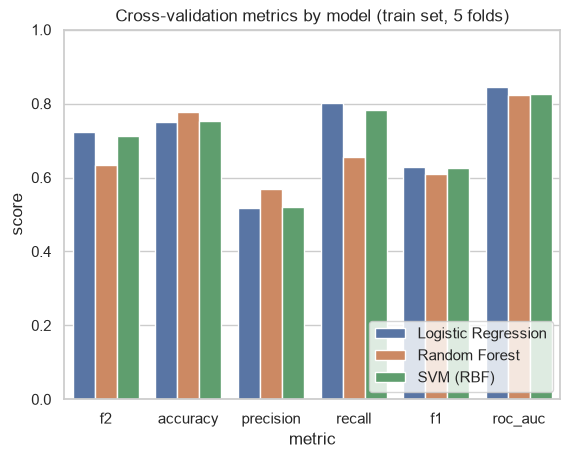

In [25]:
metric_comparison = (comparison_table[mean_columns]
                     .rename(columns=lambda column: column.replace("_mean", ""))
                     .reset_index(names="model")
                     .melt(id_vars="model", var_name="metric", value_name="score"))

axis = sns.barplot(data=metric_comparison, x="metric", y="score", hue="model")
axis.set_ylim(0, 1)
axis.set_title("Cross-validation metrics by model (train set, 5 folds)")
axis.legend(loc="lower right")
plt.show()

**Confusion matrices.** They are built from *out-of-fold* predictions: each training customer is predicted by
the model trained on the other 4 folds. This gives an honest view of the errors without touching the test set.
The bottom-left cell (**false negatives**) is the costliest: customers who actually leave but the model misses.

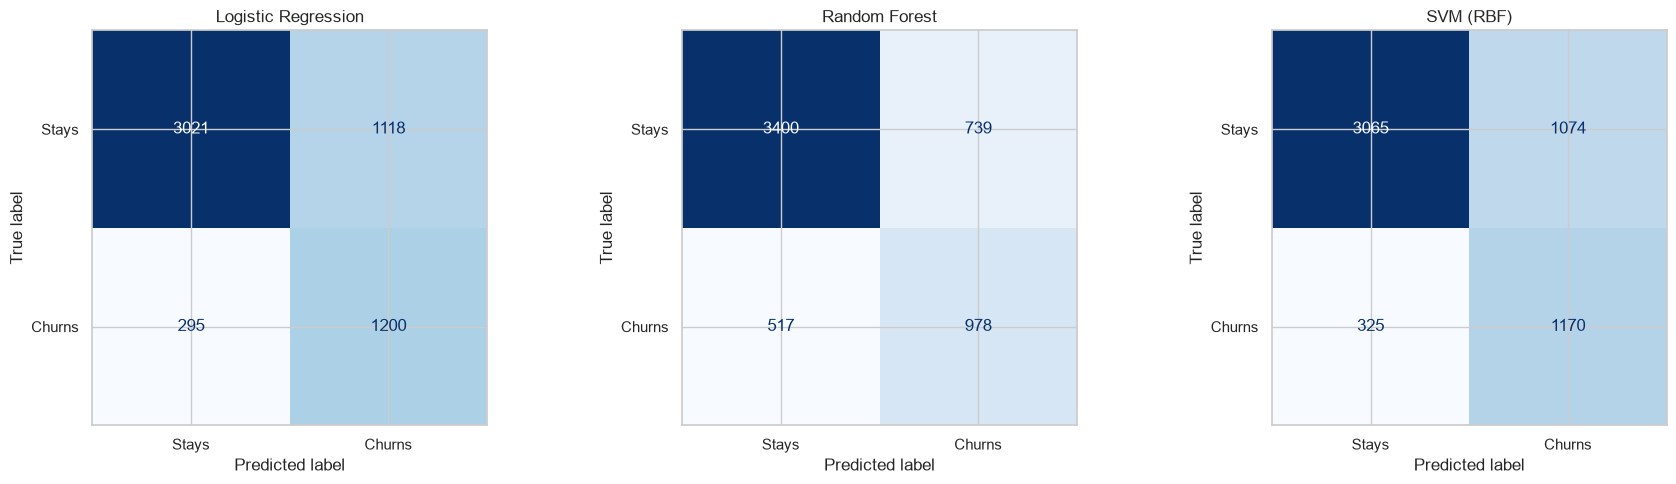

In [26]:
figure, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, (model_name, predictions) in zip(axes, out_of_fold_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(target_train, predictions, display_labels=["Stays", "Churns"],
                                            cmap="Blues", colorbar=False, ax=axis)
    axis.set_title(model_name)
plt.tight_layout()
plt.show()

#### Business impact of each type of error

Not all errors cost the same for the company:

| Error | Meaning | Business cost |
|---|---|---|
| **False negative (FN)** | The customer leaves, but the model said they would stay | The company does nothing and **loses all future revenue** from that customer. |
| **False positive (FP)** | The model flags a customer who was not going to leave | A **wasted retention contact** (call or incentive), and a possible annoyance for a loyal customer. |

The FN cost is measured with **real data**: `MonthlyCharges` is exactly the monthly revenue lost per churner.
Only the cost per contact is a **hypothetical assumption**, declared below.
The figures come from the out-of-fold predictions on the training set (5,634 customers); the test set is not used.

In [27]:
HYPOTHETICAL_COST_PER_CONTACT = 10  # USD per retention call/incentive — assumption, not data

monthly_charges_train = features_train["MonthlyCharges"].to_numpy()
actual_churn_train = target_train.to_numpy()

impact_rows = {}
for model_name, predictions in out_of_fold_predictions.items():
    true_positive_mask = (actual_churn_train == 1) & (predictions == 1)
    false_negative_mask = (actual_churn_train == 1) & (predictions == 0)
    false_positive_mask = (actual_churn_train == 0) & (predictions == 1)
    impact_rows[model_name] = {
        "churners_detected (TP)": true_positive_mask.sum(),
        "churners_missed (FN)": false_negative_mask.sum(),
        "unnecessary_contacts (FP)": false_positive_mask.sum(),
        "monthly_revenue_reachable_TP ($)": monthly_charges_train[true_positive_mask].sum(),
        "monthly_revenue_lost_FN ($)": monthly_charges_train[false_negative_mask].sum(),
        "total_contacts": true_positive_mask.sum() + false_positive_mask.sum(),
        "contacts_per_churner_found": (true_positive_mask.sum() + false_positive_mask.sum()) / true_positive_mask.sum(),
        "hypothetical_cost_of_wasted_contacts ($)": false_positive_mask.sum() * HYPOTHETICAL_COST_PER_CONTACT,
    }

business_impact_table = pd.DataFrame(impact_rows).T
business_impact_table.style.format({
    "monthly_revenue_reachable_TP ($)": "${:,.0f}", "monthly_revenue_lost_FN ($)": "${:,.0f}",
    "hypothetical_cost_of_wasted_contacts ($)": "${:,.0f}", "contacts_per_churner_found": "{:.2f}",
    "churners_detected (TP)": "{:,.0f}", "churners_missed (FN)": "{:,.0f}",
    "unnecessary_contacts (FP)": "{:,.0f}", "total_contacts": "{:,.0f}",
})

,churners_detected (TP),churners_missed (FN),unnecessary_contacts (FP),monthly_revenue_reachable_TP ($),monthly_revenue_lost_FN ($),total_contacts,contacts_per_churner_found,hypothetical_cost_of_wasted_contacts ($)
Logistic Regression,"1,200",295,"1,118","$93,604","$18,312","2,318",1.93,"$11,180"
Random Forest,978,517,739,"$76,904","$35,012","1,717",1.76,"$7,390"
SVM (RBF),"1,170",325,"1,074","$91,273","$20,643","2,244",1.92,"$10,740"


**How to read it:** `monthly_revenue_lost_FN` is revenue that walks out the door every month without the company
even trying to keep it. `contacts_per_churner_found` measures how many customers must be contacted to reach one
real churner: values close to 1 mean few loyal customers are bothered; large values mean many unnecessary calls.
This table will be revisited after optimization (Part 2) and interpretability (Part 4).

#### Initial model selection

**Logistic Regression vs SVM: a statistical tie.** Logistic Regression has the highest F2 (0.723), but the gap
with the SVM (0.711) is only 0.012, smaller than the standard deviation across folds of either model (≈0.03).
With the default hyperparameters, both models perform equally well on the primary metric. Logistic Regression
also leads in ROC-AUC (0.846 vs 0.826) and misses slightly less monthly revenue ($18,312 vs $20,643).

**Random Forest is discarded for optimization.** Its F2 (0.635) is about 0.09 below the other two, roughly three
times the fold-to-fold standard deviation, so the gap is real with default settings. In business terms, its
false negatives represent $35,012 of lost monthly revenue, almost double that of Logistic Regression.
This does not prove Random Forest is useless (it was not tuned), and it is still used in Part 4 to compare its
feature importance with SHAP.

**Selected model for optimization: SVM (RBF kernel).**
1. *It is tied with the best model* on F2, so optimizing it can realistically make it the best option.
2. *It trains faster* (≈1.9 s vs ≈4.9 s for a full cross-validation), so the same time budget allows more
   configurations to be evaluated.
3. *It has a richer hyperparameter space.* Logistic Regression's weights are **parameters** learned during
   training; its only relevant **hyperparameters** are the regularization strength `C` and the penalty type.
   The SVM has `C` (how strongly points on the wrong side of the margin are penalized: wide margin vs fewer errors),
   `gamma` (the radius of influence of each training point: how flexible the boundary is) and the kernel.
4. *It provides a real trade-off for the multi-objective optimization (Part 3).* An SVM predicts by comparing each
   new customer against its **support vectors**, and their number changes with `C` and `gamma`. More support
   vectors usually means slower inference, so F2 and inference time compete. For Logistic Regression, inference time
   is practically constant, so the Pareto front would be trivial.

**Fallback plan.** If the optimized SVM turns out too slow at inference time, Logistic Regression will be
reconsidered with its own hyperparameter search.

## Part 2. Hyperparameter optimization

**Parameters vs hyperparameters.** *Parameters* are learned by the model during training (for an SVM, which
customers become support vectors and their weights). *Hyperparameters* are chosen **before** training and control
how the model learns. Optimizing them means searching for the configuration with the best cross-validated F2.

**Common protocol for every strategy** (required for a fair comparison):

| Element | Value |
|---|---|
| Base model | `Pipeline(preprocessor → SVC(kernel="rbf", class_weight="balanced"))` |
| Data | Training set only (the test set stays isolated) |
| Validation | The same `StratifiedKFold(5)` folds defined in section 1.9 |
| Objective | Mean F2 over the 5 folds |
| Budget | **36 configurations** per strategy |

**Search space.**

| Hyperparameter | Meaning | Range | Scale |
|---|---|---|---|
| `C` | Penalty for training points on the wrong side of the margin. Small `C` → wide, tolerant margin (simpler model); large `C` → narrow margin that tries to classify every training point (risk of overfitting). | 0.01 – 100 | log |
| `gamma` | Radius of influence of each training point in the RBF kernel. Small `gamma` → smooth, almost linear boundary; large `gamma` → very curved boundary around individual points (risk of overfitting). | 0.001 – 1 | log |

A **logarithmic scale** is used because the effect of these hyperparameters is multiplicative: going from 0.01 to 0.1
changes the model as much as going from 10 to 100.

In [28]:
import optuna
from scipy.stats import loguniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEARCH_BUDGET = 36
C_RANGE = (0.01, 100)
GAMMA_RANGE = (0.001, 1)

def build_svm_pipeline(**svm_hyperparameters):
    return build_pipeline(SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE, **svm_hyperparameters))

optimization_results = {}

### 2.1 Grid Search

**How it works:** it defines a fixed list of values for each hyperparameter and evaluates **every combination**
(the Cartesian product). It is exhaustive and easy to reproduce, but the cost grows multiplicatively with each
new hyperparameter, and it can only find values that are on the grid.

Grid: 6 values of `C` × 6 values of `gamma` = **36 configurations**, evenly spaced on a log scale.

In [29]:
grid_c_values = np.logspace(np.log10(C_RANGE[0]), np.log10(C_RANGE[1]), 6)
grid_gamma_values = np.logspace(np.log10(GAMMA_RANGE[0]), np.log10(GAMMA_RANGE[1]), 6)
print("C values:    ", np.round(grid_c_values, 4))
print("gamma values:", np.round(grid_gamma_values, 4))

grid_search = GridSearchCV(build_svm_pipeline(),
                           param_grid={"model__C": grid_c_values, "model__gamma": grid_gamma_values},
                           scoring=scoring_metrics, refit=PRIMARY_METRIC, cv=cross_validation_folds, n_jobs=-1)
start_time = time.perf_counter()
grid_search.fit(features_train, target_train)
grid_search_seconds = time.perf_counter() - start_time

def summarize_sklearn_search(search, elapsed_seconds):
    best_index = search.best_index_
    return {
        "configurations_evaluated": len(search.cv_results_["params"]),
        "optimization_seconds": elapsed_seconds,
        "best_C": search.best_params_["model__C"],
        "best_gamma": search.best_params_["model__gamma"],
        **{f"cv_{metric}": search.cv_results_[f"mean_test_{metric}"][best_index] for metric in scoring_metrics},
        "f2_by_configuration": search.cv_results_[f"mean_test_{PRIMARY_METRIC}"],
    }

optimization_results["Grid Search"] = summarize_sklearn_search(grid_search, grid_search_seconds)
print(f"Best F2: {grid_search.best_score_:.4f} with {grid_search.best_params_}  |  time: {grid_search_seconds:.1f} s")

C values:     [1.00000e-02 6.31000e-02 3.98100e-01 2.51190e+00 1.58489e+01 1.00000e+02]
gamma values: [0.001  0.004  0.0158 0.0631 0.2512 1.    ]


Best F2: 0.7244 with {'model__C': np.float64(0.3981071705534973), 'model__gamma': np.float64(0.003981071705534973)}  |  time: 64.4 s


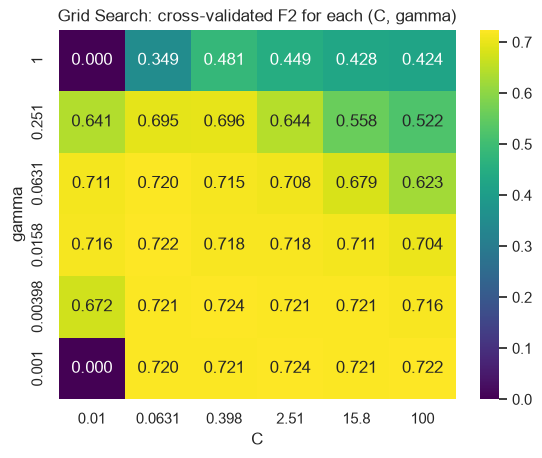

In [30]:
grid_f2_matrix = (pd.DataFrame(grid_search.cv_results_["params"])
                  .assign(f2=grid_search.cv_results_[f"mean_test_{PRIMARY_METRIC}"])
                  .pivot(index="model__gamma", columns="model__C", values="f2"))
grid_f2_matrix.index = [f"{value:.3g}" for value in grid_f2_matrix.index]
grid_f2_matrix.columns = [f"{value:.3g}" for value in grid_f2_matrix.columns]

axis = sns.heatmap(grid_f2_matrix, annot=True, fmt=".3f", cmap="viridis")
axis.set_xlabel("C")
axis.set_ylabel("gamma")
axis.set_title("Grid Search: cross-validated F2 for each (C, gamma)")
axis.invert_yaxis()
plt.show()

### 2.2 Random Search

**How it works:** instead of a fixed grid, each configuration is **sampled at random** from a probability
distribution over the range (here, log-uniform). With the same budget it explores **36 different values of each
hyperparameter** instead of only 6, which helps when only one hyperparameter really matters. It does not learn from
previous trials: each sample is independent.

In [31]:
random_search = RandomizedSearchCV(build_svm_pipeline(),
                                   param_distributions={"model__C": loguniform(*C_RANGE),
                                                        "model__gamma": loguniform(*GAMMA_RANGE)},
                                   n_iter=SEARCH_BUDGET, scoring=scoring_metrics, refit=PRIMARY_METRIC,
                                   cv=cross_validation_folds, n_jobs=-1, random_state=RANDOM_STATE)
start_time = time.perf_counter()
random_search.fit(features_train, target_train)
random_search_seconds = time.perf_counter() - start_time

optimization_results["Random Search"] = summarize_sklearn_search(random_search, random_search_seconds)
print(f"Best F2: {random_search.best_score_:.4f} with {random_search.best_params_}  |  time: {random_search_seconds:.1f} s")

Best F2: 0.7244 with {'model__C': np.float64(0.358681649862755), 'model__gamma': np.float64(0.006516990611177174)}  |  time: 57.4 s


### 2.3 Bayesian optimization with TPE (Optuna)

**How it works:** TPE (*Tree-structured Parzen Estimator*) **learns from previous trials**. After a few random
start-up trials, it splits the configurations evaluated so far into "good" (top results) and "bad", models the
density of each group, $l(x)$ and $g(x)$, and proposes the next configuration where the ratio $l(x)/g(x)$ is highest,
that is, where good configurations are likely and bad ones unlikely. This concentrates the budget on promising
regions instead of spending it uniformly.

In [32]:
def svm_f2_objective(trial):
    svm_hyperparameters = {
        "C": trial.suggest_float("C", *C_RANGE, log=True),
        "gamma": trial.suggest_float("gamma", *GAMMA_RANGE, log=True),
    }
    fold_scores = cross_validate(build_svm_pipeline(**svm_hyperparameters), features_train, target_train,
                                 cv=cross_validation_folds, scoring=scoring_metrics, n_jobs=-1)
    for metric in scoring_metrics:
        trial.set_user_attr(f"cv_{metric}", fold_scores[f"test_{metric}"].mean())
    return fold_scores[f"test_{PRIMARY_METRIC}"].mean()

tpe_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
start_time = time.perf_counter()
tpe_study.optimize(svm_f2_objective, n_trials=SEARCH_BUDGET)
tpe_seconds = time.perf_counter() - start_time

optimization_results["TPE (Optuna)"] = {
    "configurations_evaluated": len(tpe_study.trials),
    "optimization_seconds": tpe_seconds,
    "best_C": tpe_study.best_params["C"],
    "best_gamma": tpe_study.best_params["gamma"],
    **{f"cv_{metric}": tpe_study.best_trial.user_attrs[f"cv_{metric}"] for metric in scoring_metrics},
    "f2_by_configuration": np.array([trial.value for trial in tpe_study.trials]),
}
print(f"Best F2: {tpe_study.best_value:.4f} with {tpe_study.best_params}  |  time: {tpe_seconds:.1f} s")

Best F2: 0.7245 with {'C': 0.23735462091881923, 'gamma': 0.007431125324075301}  |  time: 100.6 s


### 2.4 Comparison of strategies

In [33]:
strategy_comparison = pd.DataFrame(optimization_results).T.drop(columns="f2_by_configuration")
baseline_svm_f2 = comparison_table.loc["SVM (RBF)", f"{PRIMARY_METRIC}_mean"]
strategy_comparison["f2_gain_vs_default_svm"] = strategy_comparison[f"cv_{PRIMARY_METRIC}"] - baseline_svm_f2
strategy_comparison = strategy_comparison.astype(float)
print(f"Default SVM (C=1, gamma='scale') F2 from section 1.9: {baseline_svm_f2:.4f}")
strategy_comparison.round(4)

Default SVM (C=1, gamma='scale') F2 from section 1.9: 0.7111


,configurations_evaluated,optimization_seconds,best_C,best_gamma,cv_f2,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,f2_gain_vs_default_svm
Grid Search,36.0,64.3929,0.3981,0.0040,0.7244,0.7355,0.5012,0.8154,0.6206,0.8408,0.0133
Random Search,36.0,57.4151,0.3587,0.0065,0.7244,0.7322,0.4974,0.8181,0.6184,0.8412,0.0133
TPE (Optuna),36.0,100.6421,0.2374,0.0074,0.7245,0.7359,0.5016,0.8154,0.6209,0.8406,0.0134


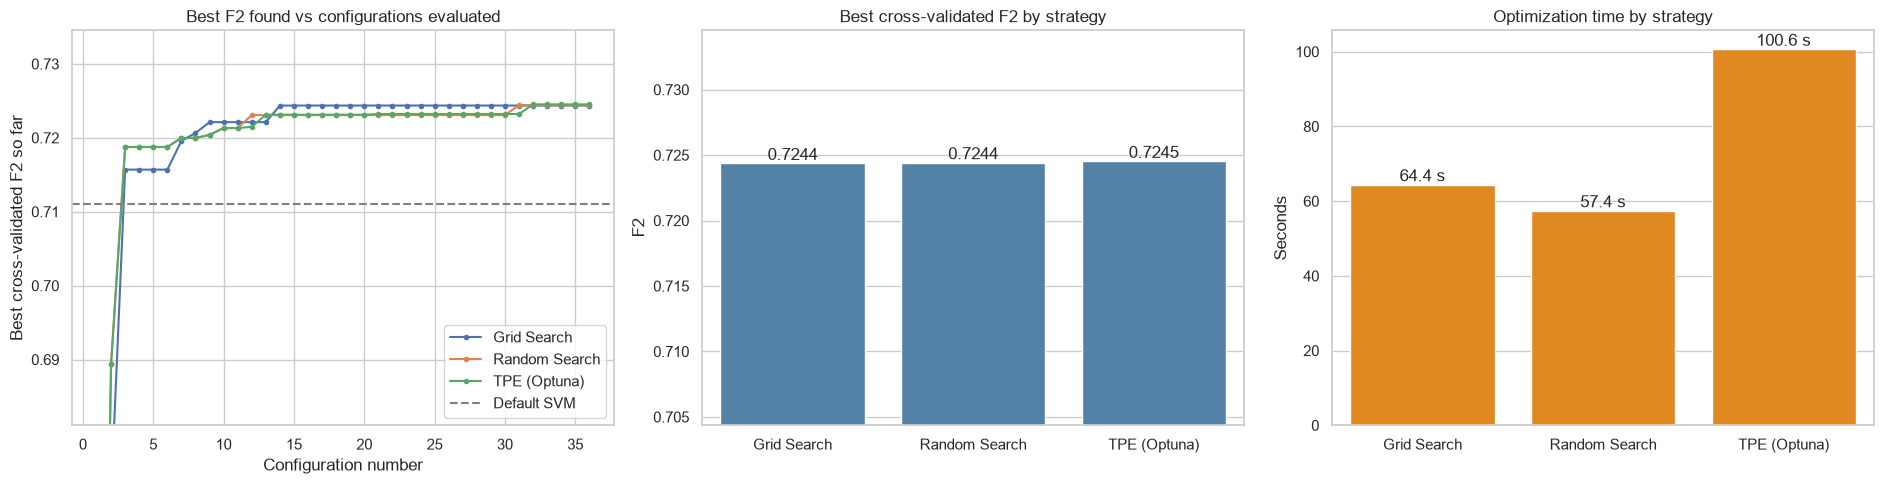

In [34]:
figure, axes = plt.subplots(1, 3, figsize=(19, 5))

for strategy_name, result in optimization_results.items():
    best_so_far = np.maximum.accumulate(result["f2_by_configuration"])
    axes[0].plot(range(1, len(best_so_far) + 1), best_so_far, marker="o", markersize=3, label=strategy_name)
axes[0].axhline(baseline_svm_f2, color="gray", linestyle="--", label="Default SVM")
axes[0].set_title("Best F2 found vs configurations evaluated")
axes[0].set_xlabel("Configuration number")
axes[0].set_ylabel("Best cross-validated F2 so far")
axes[0].set_ylim(baseline_svm_f2 - 0.03, strategy_comparison[f"cv_{PRIMARY_METRIC}"].max() + 0.01)
axes[0].legend()

sns.barplot(x=strategy_comparison.index, y=strategy_comparison[f"cv_{PRIMARY_METRIC}"], ax=axes[1], color="steelblue")
axes[1].bar_label(axes[1].containers[0], fmt="%.4f")
axes[1].set_ylim(strategy_comparison[f"cv_{PRIMARY_METRIC}"].min() - 0.02, strategy_comparison[f"cv_{PRIMARY_METRIC}"].max() + 0.01)
axes[1].set_title("Best cross-validated F2 by strategy")
axes[1].set_ylabel("F2")

sns.barplot(x=strategy_comparison.index, y=strategy_comparison["optimization_seconds"], ax=axes[2], color="darkorange")
axes[2].bar_label(axes[2].containers[0], fmt="%.1f s")
axes[2].set_title("Optimization time by strategy")
axes[2].set_ylabel("Seconds")
axes[1].set_xlabel("")
axes[2].set_xlabel("")
plt.tight_layout()
plt.show()

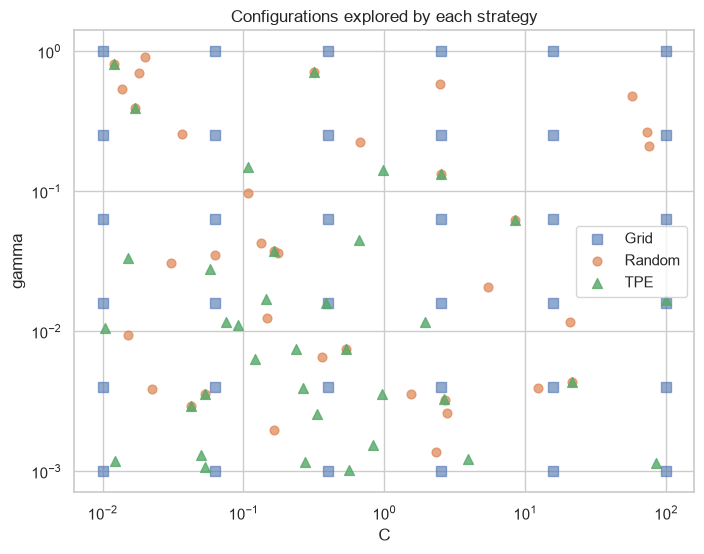

In [35]:
random_points = pd.DataFrame(random_search.cv_results_["params"])
tpe_points = pd.DataFrame([trial.params for trial in tpe_study.trials])
grid_points = pd.DataFrame(grid_search.cv_results_["params"])

figure, axis = plt.subplots(figsize=(8, 6))
axis.scatter(grid_points["model__C"], grid_points["model__gamma"], marker="s", s=60, label="Grid", alpha=0.6)
axis.scatter(random_points["model__C"], random_points["model__gamma"], marker="o", s=40, label="Random", alpha=0.7)
axis.scatter(tpe_points["C"], tpe_points["gamma"], marker="^", s=50, label="TPE", alpha=0.8)
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("C")
axis.set_ylabel("gamma")
axis.set_title("Configurations explored by each strategy")
axis.legend()
plt.show()

#### Advantages, limitations and selected strategy

| Strategy | Advantages | Limitations |
|---|---|---|
| Grid Search | Exhaustive and fully reproducible; produces a complete map of the search space; trivially parallel. | Cost grows exponentially with the number of hyperparameters; can only find values on the grid. |
| Random Search | Explores many more distinct values per hyperparameter with the same budget; trivially parallel. | Does not learn from previous trials; results depend on luck with small budgets. |
| TPE (Optuna) | Learns from previous trials and concentrates the budget on promising regions; scales better to many hyperparameters. | Sequential by nature (each trial depends on the previous ones), so it is slower in wall-clock time; more complex. |

**Results.** The three strategies reached practically the same cross-validated F2 (0.7244–0.7245), an improvement
of about +0.013 over the default SVM. The differences between strategies (≈0.0001) are negligible compared with
the fold-to-fold standard deviation (≈0.03). The Grid Search heatmap explains why: the good region is a wide
plateau (small `gamma`, almost any `C`), so with only two hyperparameters and 36 trials every strategy finds it.
The heatmap also shows that `gamma` is the critical hyperparameter: large values cause overfitting regardless of `C`,
and the combination of very small `C` with extreme `gamma` never predicts churn (F2 = 0).

**Selected strategy: Grid Search.** With the same F2, it was the fastest (54 s vs 91 s for TPE), and the search
only needs to run once before training the final model, so its cost is acceptable. It also provides the complete
F2 map, which shows that the optimum is a stable plateau rather than a fragile single point. This choice is valid
because the space has only two hyperparameters; with five or more, Grid Search would grow exponentially and TPE
would be the better option.

**Selected hyperparameters:** `C` and `gamma` from the best Grid Search configuration (shown in section 2.1).

## Part 3. Multi-objective optimization

### 3.1 Formulation

Part 2 optimized a single objective. In production, a churn model must also be **cheap and fast**: it scores
the whole customer base periodically and answers instantly inside the Streamlit app. For an SVM, prediction time
grows with the number of **support vectors**, which depends on `C` and `gamma`, so accuracy and speed can compete.

Let $\theta = (C, \gamma)$ be the SVM hyperparameters. The two objectives are:

$$\max_{\theta} \; f_1(\theta) = \frac{1}{5} \sum_{k=1}^{5} F_2^{(k)}(\theta)
\qquad\qquad
\min_{\theta} \; f_2(\theta) = \frac{1000}{N_{val}} \sum_{k=1}^{5} t_{pred}^{(k)}(\theta) \;\; \text{[ms per 1,000 customers]}$$

where $F_2^{(k)}$ is the F2 on validation fold $k$, and $t_{pred}^{(k)}$ is the time (ms) the pipeline fitted on the
other folds takes to predict fold $k$ (median of 3 repetitions, measured sequentially to avoid noise from parallel jobs).
The same folds, search space and budget (36 configurations) as in Part 2 are used.

**Pareto dominance.** Configuration A *dominates* B if it is at least as good in both objectives and strictly better
in one. The **Pareto front** is the set of non-dominated configurations: improving one objective along it always
worsens the other.

**Algorithm: NSGA-II** (*Non-dominated Sorting Genetic Algorithm II*). It evolves a population of configurations:
(1) sorts them into successive non-dominated fronts, (2) inside each front, prefers configurations in less crowded
regions (*crowding distance*) to keep the front diverse, and (3) creates new configurations by crossover and mutation
of the best ones. Here: population of 12 × 3 generations = 36 configurations.

In [36]:
def measure_prediction_milliseconds(fitted_pipeline, validation_features, repetitions=3):
    elapsed_times = []
    for _ in range(repetitions):
        start_time = time.perf_counter()
        fitted_pipeline.predict(validation_features)
        elapsed_times.append(time.perf_counter() - start_time)
    return np.median(elapsed_times) * 1000

fold_validation_indices = [validation_index for _, validation_index in cross_validation_folds.split(features_train, target_train)]

def evaluate_f2_and_speed(svm_hyperparameters):
    """Same protocol for every configuration: 5-fold CV F2 + sequential prediction time on each validation fold."""
    fold_results = cross_validate(build_svm_pipeline(**svm_hyperparameters), features_train, target_train,
                                  cv=cross_validation_folds, scoring={"f2": f2_scorer, "recall": "recall", "precision": "precision"},
                                  return_estimator=True, n_jobs=-1)
    total_prediction_milliseconds = sum(
        measure_prediction_milliseconds(fitted_pipeline, features_train.iloc[validation_index])
        for fitted_pipeline, validation_index in zip(fold_results["estimator"], fold_validation_indices))
    return {
        "cv_f2": fold_results["test_f2"].mean(),
        "ms_per_1000_customers": total_prediction_milliseconds / len(features_train) * 1000,
        "support_vectors": np.mean([fitted_pipeline.named_steps["model"].n_support_.sum()
                                    for fitted_pipeline in fold_results["estimator"]]),
        "cv_recall": fold_results["test_recall"].mean(),
        "cv_precision": fold_results["test_precision"].mean(),
    }

def svm_f2_and_speed_objective(trial):
    svm_hyperparameters = {
        "C": trial.suggest_float("C", *C_RANGE, log=True),
        "gamma": trial.suggest_float("gamma", *GAMMA_RANGE, log=True),
    }
    evaluation = evaluate_f2_and_speed(svm_hyperparameters)
    for attribute in ["support_vectors", "cv_recall", "cv_precision"]:
        trial.set_user_attr(attribute, evaluation[attribute])
    return evaluation["cv_f2"], evaluation["ms_per_1000_customers"]

nsga2_study = optuna.create_study(directions=["maximize", "minimize"],
                                  sampler=optuna.samplers.NSGAIISampler(population_size=12, seed=RANDOM_STATE))
start_time = time.perf_counter()
nsga2_study.optimize(svm_f2_and_speed_objective, n_trials=SEARCH_BUDGET)
nsga2_seconds = time.perf_counter() - start_time
print(f"NSGA-II: {len(nsga2_study.trials)} configurations evaluated in {nsga2_seconds:.1f} s")

NSGA-II: 36 configurations evaluated in 255.0 s


### 3.2 Non-dominated solutions and Pareto front

In [37]:
nsga2_trials_table = pd.DataFrame([{
    "trial": trial.number,
    "C": trial.params["C"],
    "gamma": trial.params["gamma"],
    "cv_f2": trial.values[0],
    "ms_per_1000_customers": trial.values[1],
    "support_vectors": trial.user_attrs["support_vectors"],
    "cv_recall": trial.user_attrs["cv_recall"],
    "cv_precision": trial.user_attrs["cv_precision"],
} for trial in nsga2_study.trials])

pareto_trial_numbers = {trial.number for trial in nsga2_study.best_trials}
nsga2_trials_table["is_pareto_optimal"] = nsga2_trials_table["trial"].isin(pareto_trial_numbers)
pareto_front_table = (nsga2_trials_table[nsga2_trials_table["is_pareto_optimal"]]
                      .sort_values("ms_per_1000_customers").reset_index(drop=True))
print(f"Non-dominated configurations: {len(pareto_front_table)} of {len(nsga2_trials_table)}")
pareto_front_table.round(4)

Non-dominated configurations: 6 of 36


,trial,C,gamma,cv_f2,ms_per_1000_customers,support_vectors,cv_recall,cv_precision,is_pareto_optimal
0,35,75.5681,0.2115,0.5335,239.1075,2234.4,0.5445,0.4950,True
1,20,62.4514,0.0375,0.6812,240.7914,2303.8,0.7452,0.5077,True
2,25,2.6926,0.0209,0.7160,246.3377,2392.6,0.8054,0.4964,True
3,28,72.8665,0.0013,0.7211,253.8461,2396.8,0.8341,0.4679,True
4,17,2.6926,0.0032,0.7215,261.5723,2471.8,0.8321,0.4715,True
5,32,1.2030,0.0016,0.7260,271.7369,2638.8,0.8194,0.4992,True


**Placing the Grid Search winner on the same chart.** Grid Search (Part 2) only measured F2, so its best
configuration has no inference time. It is evaluated here with exactly the same protocol (same folds, same timer)
so it can be compared with the Pareto front.

In [38]:
grid_best_hyperparameters = {"C": optimization_results["Grid Search"]["best_C"],
                             "gamma": optimization_results["Grid Search"]["best_gamma"]}
grid_best_evaluation = evaluate_f2_and_speed(grid_best_hyperparameters)

grid_best_row = {"trial": "Grid best", **grid_best_hyperparameters, **grid_best_evaluation}
grid_best_is_dominated = ((nsga2_trials_table["cv_f2"] >= grid_best_evaluation["cv_f2"]) &
                          (nsga2_trials_table["ms_per_1000_customers"] <= grid_best_evaluation["ms_per_1000_customers"]) &
                          ((nsga2_trials_table["cv_f2"] > grid_best_evaluation["cv_f2"]) |
                           (nsga2_trials_table["ms_per_1000_customers"] < grid_best_evaluation["ms_per_1000_customers"]))).any()
print(f"Is the Grid Search winner dominated by any NSGA-II configuration? {grid_best_is_dominated}")
pd.DataFrame([grid_best_row]).round(4)

Is the Grid Search winner dominated by any NSGA-II configuration? True


,trial,C,gamma,cv_f2,ms_per_1000_customers,support_vectors,cv_recall,cv_precision
0,Grid best,0.3981,0.004,0.7244,279.4936,2680.0,0.8154,0.5012


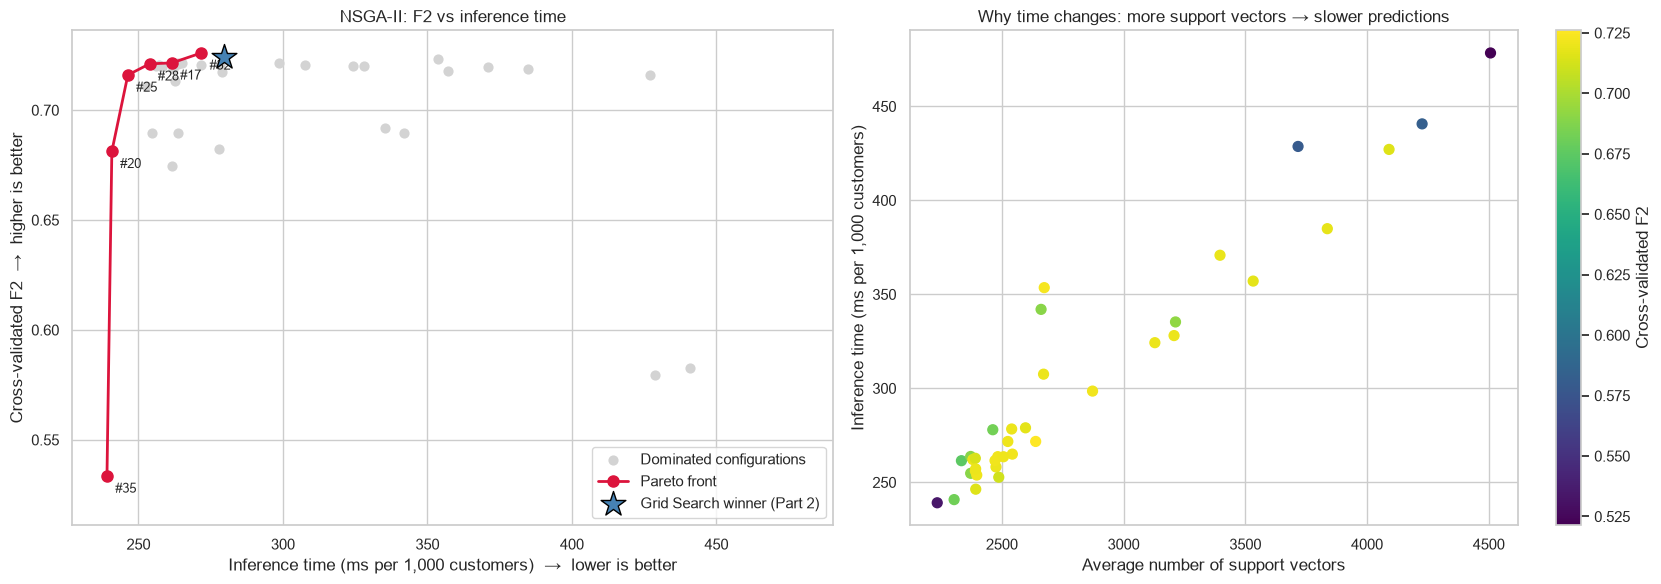

In [39]:
figure, axes = plt.subplots(1, 2, figsize=(17, 6))

dominated_trials = nsga2_trials_table[~nsga2_trials_table["is_pareto_optimal"]]
axes[0].scatter(dominated_trials["ms_per_1000_customers"], dominated_trials["cv_f2"],
                color="lightgray", s=40, label="Dominated configurations")
axes[0].plot(pareto_front_table["ms_per_1000_customers"], pareto_front_table["cv_f2"],
             color="crimson", marker="o", markersize=8, linewidth=2, label="Pareto front")
for _, pareto_row in pareto_front_table.iterrows():
    axes[0].annotate(f"#{int(pareto_row['trial'])}", (pareto_row["ms_per_1000_customers"], pareto_row["cv_f2"]),
                     textcoords="offset points", xytext=(6, -12), fontsize=9)
axes[0].scatter(grid_best_evaluation["ms_per_1000_customers"], grid_best_evaluation["cv_f2"],
                marker="*", s=350, color="steelblue", edgecolor="black", zorder=5, label="Grid Search winner (Part 2)")
axes[0].set_xlabel("Inference time (ms per 1,000 customers)  →  lower is better")
axes[0].set_ylabel("Cross-validated F2  →  higher is better")
axes[0].set_title("NSGA-II: F2 vs inference time")
axes[0].legend(loc="lower right")

scatter = axes[1].scatter(nsga2_trials_table["support_vectors"], nsga2_trials_table["ms_per_1000_customers"],
                          c=nsga2_trials_table["cv_f2"], cmap="viridis", s=50)
figure.colorbar(scatter, ax=axes[1], label="Cross-validated F2")
axes[1].set_xlabel("Average number of support vectors")
axes[1].set_ylabel("Inference time (ms per 1,000 customers)")
axes[1].set_title("Why time changes: more support vectors → slower predictions")
plt.tight_layout()
plt.show()

### 3.3 Trade-off analysis and selected solution

**Trade-offs along the front.** Moving from the fastest configurations to the most accurate ones, F2 first rises
sharply (the fastest extreme detects churners poorly) and then flattens: near the top of the front, gaining a few
thousandths of F2 costs roughly 10–15% more inference time. The right panel shows the mechanism: inference time grows
almost linearly with the number of support vectors.

**Where the Grid Search winner lies.** Evaluated with the same protocol, the Part 2 winner is **not dominated** by any
NSGA-II configuration: it sits on the high-F2 end of the front. Optimizing F2 alone already produced a Pareto-optimal
model, but not the fastest one.

**Selected solution: the Grid Search winner.** The "knee" of the front is about 10% faster but has a slightly lower F2.
Both differences are small: the F2 gap is within the fold-to-fold noise, and the time gap is a few hundredths of a
millisecond per customer, irrelevant for scoring this customer base (even millions of customers would take only
seconds more). Given that speed is not a bottleneck, the model with the highest F2 is preferred, because for this
business a missed churner (false negative) is the most expensive error. The Grid configuration is also fixed and fully
reproducible, while the trial numbers of NSGA-II change between runs because measured times vary slightly.

A different business context would change this choice: a company scoring hundreds of millions of events in real time,
or paying per CPU-second, should pick the knee of the front.

## Part 4. Final model and test evaluation

The model selection is now **closed**: SVM (RBF) with the Grid Search hyperparameters. The final pipeline is trained
on the whole training set and evaluated **once** on the isolated test set.

`probability=True` is enabled so the model returns a churn **probability** (needed for the risk ranking, SHAP, LIME
and the Streamlit app). An SVM natively outputs only a distance to the boundary; with this option scikit-learn calibrates
that distance into a probability using Platt scaling (a logistic regression fitted with internal cross-validation).

In [40]:
import warnings
# scikit-learn 1.9 deprecates SVC(probability=True) in favour of CalibratedClassifierCV; both apply Platt scaling.
warnings.filterwarnings("ignore", message="The `probability` parameter was deprecated")

final_hyperparameters = {"C": optimization_results["Grid Search"]["best_C"],
                         "gamma": optimization_results["Grid Search"]["best_gamma"]}
final_pipeline = build_svm_pipeline(probability=True, **final_hyperparameters)
final_pipeline.fit(features_train, target_train)
print(f"Final model: SVM (RBF) with C = {final_hyperparameters['C']:.4f}, gamma = {final_hyperparameters['gamma']:.4f}")

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

test_predictions = final_pipeline.predict(features_test)
test_churn_probabilities = final_pipeline.predict_proba(features_test)[:, 1]

test_metrics = {
    "f2": fbeta_score(target_test, test_predictions, beta=2),
    "accuracy": accuracy_score(target_test, test_predictions),
    "precision": precision_score(target_test, test_predictions),
    "recall": recall_score(target_test, test_predictions),
    "f1": f1_score(target_test, test_predictions),
    "roc_auc": roc_auc_score(target_test, test_churn_probabilities),
}
cross_validation_metrics = {metric: optimization_results["Grid Search"][f"cv_{metric}"] for metric in test_metrics}
pd.DataFrame({"cross_validation (train)": cross_validation_metrics, "test": test_metrics}).round(4)

Final model: SVM (RBF) with C = 0.3981, gamma = 0.0040


,cross_validation (train),test
f2,0.7244,0.7143
accuracy,0.7355,0.7246
precision,0.5012,0.4887
recall,0.8154,0.8075
f1,0.6206,0.6089
roc_auc,0.8408,0.8350


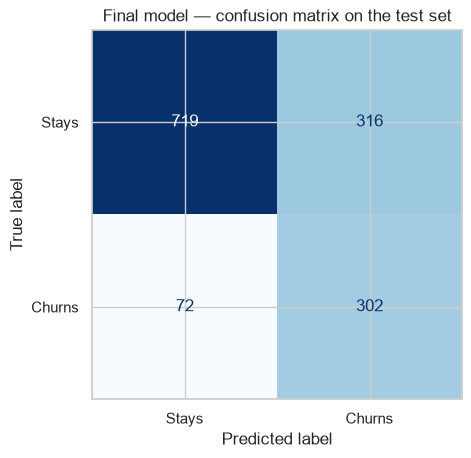

In [41]:
ConfusionMatrixDisplay.from_predictions(target_test, test_predictions, display_labels=["Stays", "Churns"],
                                        cmap="Blues", colorbar=False)
plt.title("Final model — confusion matrix on the test set")
plt.show()

## Part 5. Explainable AI: SHAP and LIME

### 5.1 SHAP

**Idea.** SHAP comes from cooperative game theory. The variables are "players" that together produce a prediction.
The Shapley value of a variable is its fair share of the difference between this customer's predicted churn probability
and the average prediction, computed by considering the variable's contribution across combinations of the other variables.
The contributions are **additive**:

$$\text{predicted probability} = \underbrace{E[f(X)]}_{\text{average prediction}} + \sum_{j} \phi_j$$

A positive $\phi_j$ pushes the customer towards **churn**; a negative one pushes towards **staying**.

**How it is applied here.**
- The SVM has no fast exact SHAP algorithm (unlike tree models), so `KernelExplainer` is used: a model-agnostic
  approximation based on sampling. To keep it tractable, the background (the "average customer") is summarized with
  k-means into 10 representative training customers, and 150 test customers are explained.
- SHAP is computed on the **preprocessed** features the SVM actually sees (scaled numbers and one-hot columns).
  For readability, the one-hot columns of each original variable are then **summed** back into one value per variable
  (Shapley values are additive, so this is exact).
- The explained output is the **probability of churn** (class 1).

In [42]:
import shap

fitted_preprocessor = final_pipeline.named_steps["preprocessor"]
fitted_svm = final_pipeline.named_steps["model"]
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

def churn_probability_from_transformed(transformed_rows):
    return fitted_svm.predict_proba(transformed_rows)[:, 1]

def original_variable_of(transformed_name):
    without_prefix = transformed_name.split("__", 1)[1]
    return next(column for column in features_train.columns
                if without_prefix == column or without_prefix.startswith(column + "_"))

transformed_to_original = [original_variable_of(name) for name in transformed_feature_names]

training_transformed = fitted_preprocessor.transform(features_train)
shap_background = shap.kmeans(training_transformed, 10)
shap_explainer = shap.KernelExplainer(churn_probability_from_transformed, shap_background)
print(f"Average predicted churn probability (SHAP base value): {shap_explainer.expected_value:.3f}")

Average predicted churn probability (SHAP base value): 0.312


**Customers explained individually** (from the test set): one churner the model detected with high confidence,
one loyal customer with very low risk, and one **false negative** (a churner the model missed), which shows what
happens when the model is wrong.

In [43]:
test_results = features_test.assign(actual_churn=target_test.to_numpy(), predicted_churn=test_predictions,
                                    churn_probability=test_churn_probabilities)

true_positives = test_results[(test_results["actual_churn"] == 1) & (test_results["predicted_churn"] == 1)]
true_negatives = test_results[(test_results["actual_churn"] == 0) & (test_results["predicted_churn"] == 0)]
false_negatives = test_results[(test_results["actual_churn"] == 1) & (test_results["predicted_churn"] == 0)]

selected_customers = {
    "Detected churner (high risk)": true_positives["churn_probability"].idxmax(),
    "Loyal customer (low risk)": true_negatives["churn_probability"].idxmin(),
    "Missed churner (false negative)": false_negatives["churn_probability"].idxmin(),
}
test_results.loc[list(selected_customers.values()),
                 ["tenure", "Contract", "InternetService", "PaymentMethod", "MonthlyCharges",
                  "actual_churn", "predicted_churn", "churn_probability"]].set_axis(list(selected_customers.keys())).round(3)

,tenure,Contract,InternetService,PaymentMethod,MonthlyCharges,actual_churn,predicted_churn,churn_probability
Detected churner (high risk),1,Month-to-month,Fiber optic,Electronic check,95.10,1,1,0.813
Loyal customer (low risk),72,Two year,No,Bank transfer (automatic),19.55,0,0,0.009
Missed churner (false negative),55,Two year,DSL,Bank transfer (automatic),57.55,1,0,0.024


In [44]:
other_test_indices = features_test.drop(index=list(selected_customers.values())).sample(147, random_state=RANDOM_STATE).index
shap_customer_indices = list(selected_customers.values()) + list(other_test_indices)
shap_customers_transformed = fitted_preprocessor.transform(features_test.loc[shap_customer_indices])

start_time = time.perf_counter()
transformed_shap_values = shap_explainer.shap_values(shap_customers_transformed, nsamples=500, silent=True)
print(f"SHAP values for {len(shap_customer_indices)} customers computed in {time.perf_counter() - start_time:.0f} s")

original_shap_values = (pd.DataFrame(transformed_shap_values, columns=transformed_feature_names, index=shap_customer_indices)
                        .T.groupby(transformed_to_original, sort=False).sum().T)
original_shap_values.shape

SHAP values for 150 customers computed in 306 s


(150, 19)

#### Global explanation: which variables drive the predictions?

Mean absolute SHAP value per original variable: how much, on average, each variable moves the predicted churn
probability (in either direction), taking into account its interactions with the other variables. The absolute value
is used so that positive and negative contributions do not cancel out; the **direction** of each effect is shown in
the individual explanations below.

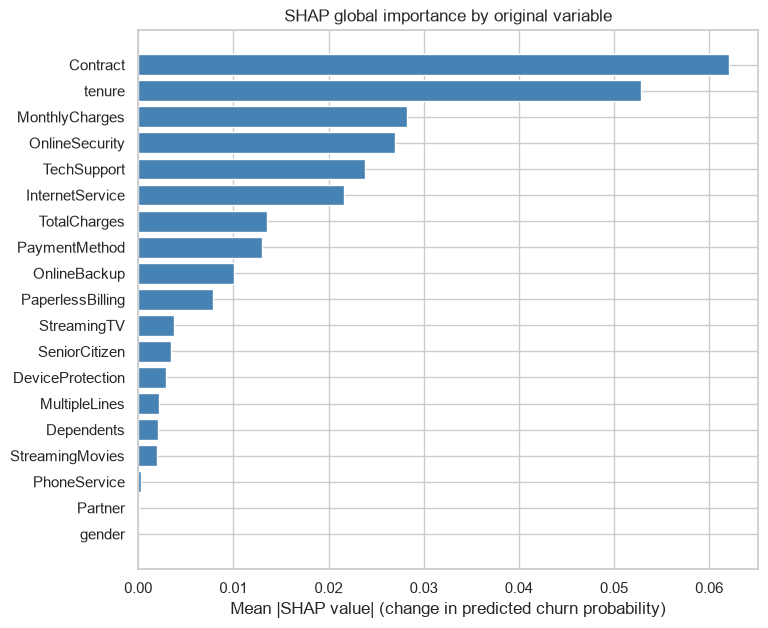

In [45]:
global_shap_importance = original_shap_values.abs().mean().sort_values()

figure, axis = plt.subplots(figsize=(8, 7))
axis.barh(global_shap_importance.index, global_shap_importance.values, color="steelblue")
axis.set_xlabel("Mean |SHAP value| (change in predicted churn probability)")
axis.set_title("SHAP global importance by original variable")
plt.show()

#### Local explanations: why did the model predict this for this customer?

Each waterfall starts at the average predicted probability $E[f(X)]$ (bottom) and adds the contribution of each
variable until it reaches this customer's predicted churn probability $f(x)$ (top). Red bars push towards churn,
blue bars towards staying. Labels show the customer's **original** values.

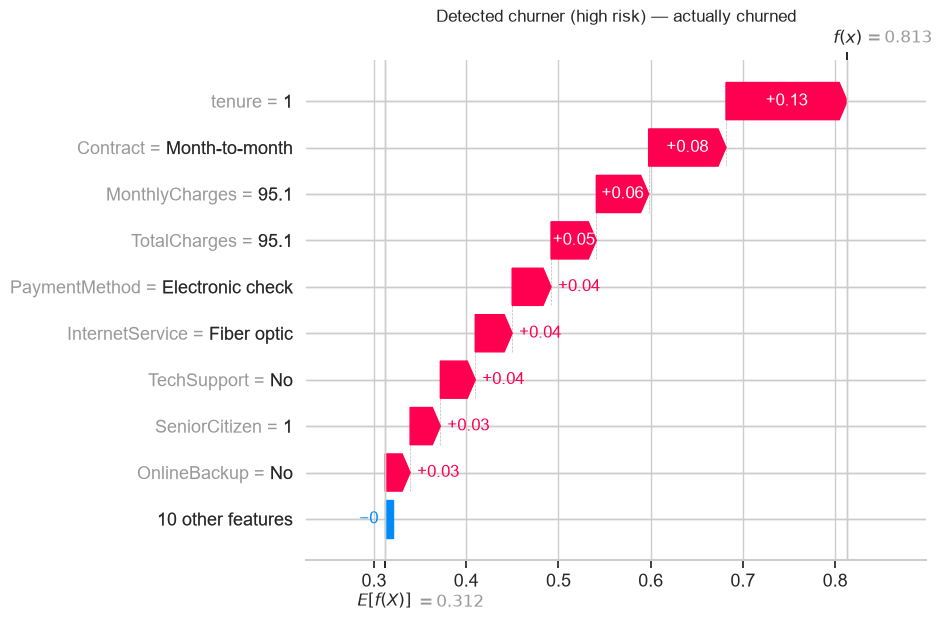

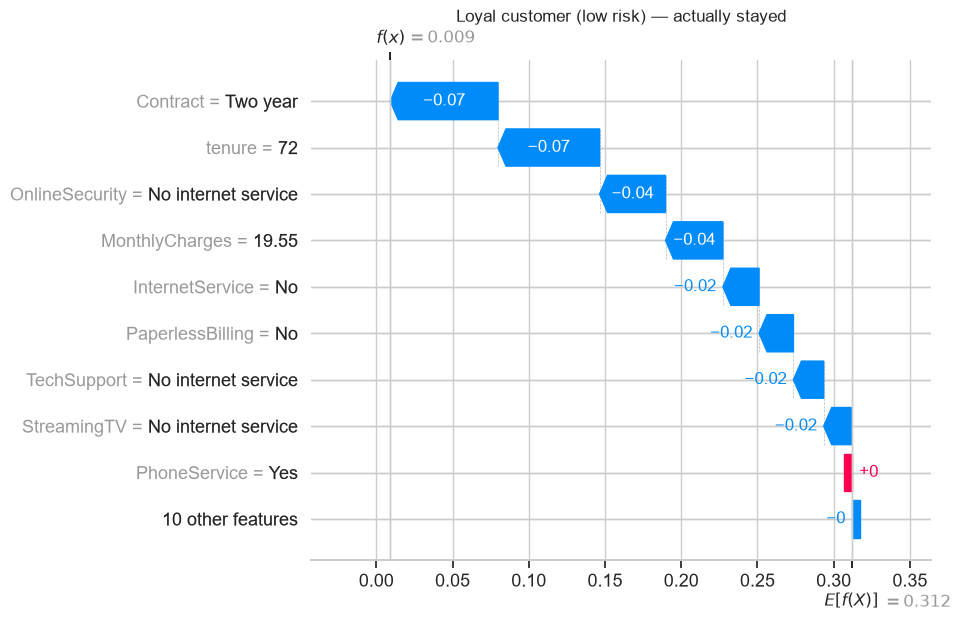

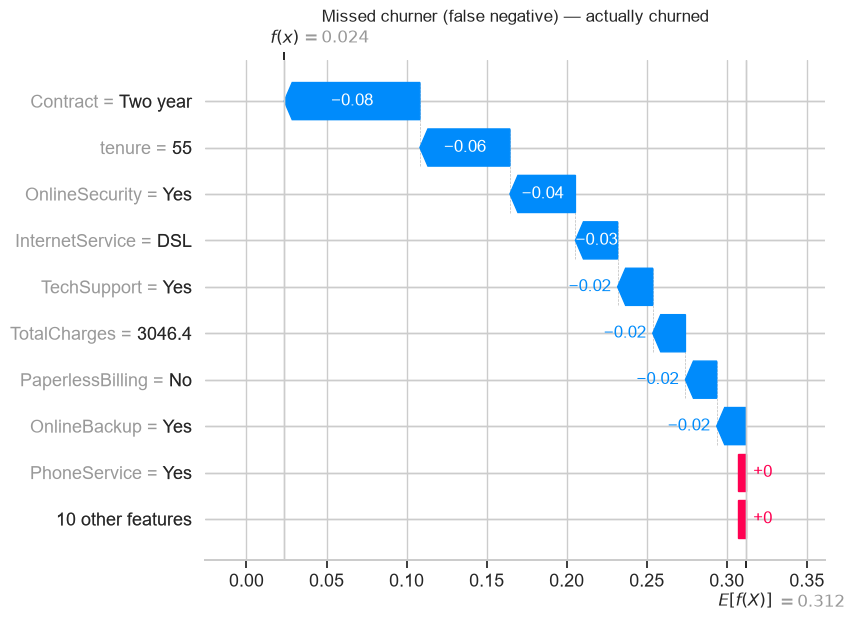

In [46]:
for customer_label, customer_index in selected_customers.items():
    customer_shap_values = original_shap_values.loc[customer_index]
    customer_original_values = features_test.loc[customer_index]
    readable_feature_names = [f"{variable} = {customer_original_values[variable]}" for variable in customer_shap_values.index]
    customer_explanation = shap.Explanation(values=customer_shap_values.to_numpy(),
                                            base_values=shap_explainer.expected_value,
                                            feature_names=readable_feature_names)
    shap.plots.waterfall(customer_explanation, max_display=10, show=False)
    actual_label = "churned" if target_test.loc[customer_index] == 1 else "stayed"
    plt.title(f"{customer_label} — actually {actual_label}", fontsize=12)
    plt.show()

#### SHAP interpretation

**Global.** `Contract` and `tenure` are by far the variables that move the SVM's predictions the most, followed by
`MonthlyCharges`, `OnlineSecurity`, `TechSupport` and `InternetService`. `gender` and `Partner` contribute practically
nothing. This ranking is consistent with the bivariate analysis of section 1.7.

**How to read a waterfall.** It starts at the average predicted churn probability $E[f(X)]$ (bottom) and adds the
contribution of each variable of this customer until it reaches the customer's predicted probability $f(x)$ (top).
Red bars **increase** the churn risk, blue bars **decrease** it, and the contributions always add up exactly to $f(x)$.
Labels show the customer's original values, so no knowledge of the preprocessing is needed to read them.

**The three customers tell three stories:**

| Customer | Predicted risk | What SHAP shows |
|---|---|---|
| Detected churner | High | Almost every contribution is red: a brand-new customer (1 month), a high monthly charge, a month-to-month contract, electronic check payment and no security or technical support add up to a very high risk. |
| Loyal customer | Very low | Almost every contribution is blue: a long tenure, a two-year contract and a low monthly charge. |
| Missed churner (false negative) | Very low, but left | Its profile looks loyal (long tenure, two-year contract, technical support and online security), so every variable pushes towards staying. The reason this customer left is **not captured by the available data** (e.g. relocation, a competitor's offer, a service incident). |

The false negative is important for the business: the model fails on customers whose reason to leave is invisible
in the data, and SHAP makes it possible to see exactly why it failed instead of treating the error as a mystery.

**From explanation to retention action.** Because the explanation is per customer, the retention team can choose the
action that addresses *that* customer's risk drivers instead of sending the same offer to everyone:

| Risk driver shown by SHAP | Proposed retention action (hypothesis to test) |
|---|---|
| Month-to-month contract | Offer a discounted one- or two-year contract (e.g. first months at a reduced price). |
| Very short tenure (new customer) | Onboarding program during the first 6 months: welcome call, usage check-ins, early-life support. |
| High monthly charge | Plan review: suggest a cheaper plan that fits the customer's real usage, or a loyalty discount. |
| No online security / technical support | Free trial of the security or technical support add-on for a few months. |
| Electronic check payment | Incentive to switch to automatic payment (small bill credit). |

For example, for the detected churner the message to the retention agent would be: *"81% churn risk, mainly because
the customer is new, pays a high monthly charge and has no contract. Suggested action: a discounted annual contract
including technical support."*

**Caveat: association, not causation.** SHAP explains what the model **associates** with risk; it does not prove that
changing a variable will retain the customer. For example, forcing a two-year contract does not guarantee loyalty,
because customers who choose long contracts were probably already more committed (self-selection). Each action above
should be validated with a controlled experiment (A/B test: contacted group vs control group) before scaling it.

### 5.2 LIME

**Idea.** LIME (*Local Interpretable Model-agnostic Explanations*) explains one prediction by imitating the model
**only around that customer** with a simple linear model:
1. It generates thousands of synthetic "neighbors" by perturbing the customer's values (categorical values are
   resampled from their training frequencies; numeric values are sampled from their training distribution).
2. It asks the SVM for the churn probability of every neighbor.
3. It weights each neighbor by its similarity to the original customer (exponential kernel on the distance).
4. It fits a weighted linear regression; its coefficients are the explanation.

$$\text{explanation}(x) = \arg\min_{g \in G} \; \mathcal{L}(f, g, \pi_x) + \Omega(g)$$

where $f$ is the SVM, $g$ the simple linear model, $\pi_x$ the proximity weights around customer $x$, and $\Omega(g)$
limits its complexity (here, the 10 most relevant variables). Numeric variables are discretized into quartile ranges
(e.g. `tenure <= 9`), which makes the explanation easier to read.

**How it is applied here.** LIME works on the **original** variables (before preprocessing): categorical values are
encoded as integer codes only so that LIME can perturb them, and the prediction function decodes them back and calls
the full pipeline (preprocessing + SVM). The same three test customers explained with SHAP are explained here.

In [47]:
from lime.lime_tabular import LimeTabularExplainer

category_values_by_column = {column: sorted(features_train[column].unique().tolist()) for column in categorical_features}
lime_column_order = list(features_train.columns)
lime_categorical_indices = [lime_column_order.index(column) for column in categorical_features]

def encode_for_lime(original_rows):
    encoded_rows = original_rows[lime_column_order].copy()
    for column in categorical_features:
        encoded_rows[column] = encoded_rows[column].map({value: code for code, value in enumerate(category_values_by_column[column])})
    return encoded_rows.to_numpy(dtype=float)

def churn_probability_from_lime_rows(encoded_rows):
    decoded_rows = pd.DataFrame(encoded_rows, columns=lime_column_order)
    for column in categorical_features:
        decoded_rows[column] = [category_values_by_column[column][int(round(code))] for code in decoded_rows[column]]
    for column in numeric_features:
        decoded_rows[column] = decoded_rows[column].astype(float)
    return final_pipeline.predict_proba(decoded_rows)

lime_explainer = LimeTabularExplainer(
    training_data=encode_for_lime(features_train),
    feature_names=lime_column_order,
    categorical_features=lime_categorical_indices,
    categorical_names={index: category_values_by_column[column] for index, column in zip(lime_categorical_indices, categorical_features)},
    class_names=["Stays", "Churns"],
    discretize_continuous=True,
    mode="classification",
    random_state=RANDOM_STATE,
)

lime_explanations = {}
for customer_label, customer_index in selected_customers.items():
    customer_encoded = encode_for_lime(features_test.loc[[customer_index]])[0]
    lime_explanations[customer_label] = lime_explainer.explain_instance(
        customer_encoded, churn_probability_from_lime_rows, num_features=10, num_samples=3000, labels=(1,))
    print(f"{customer_label}: SVM churn probability = {test_churn_probabilities[features_test.index.get_loc(customer_index)]:.3f}"
          f"  |  LIME local model prediction = {lime_explanations[customer_label].local_pred[0]:.3f}")

Detected churner (high risk): SVM churn probability = 0.813  |  LIME local model prediction = 0.586


Loyal customer (low risk): SVM churn probability = 0.009  |  LIME local model prediction = -0.156


Missed churner (false negative): SVM churn probability = 0.024  |  LIME local model prediction = -0.050


Each bar is a coefficient of LIME's local linear model: **green pushes towards churn**, **red pushes towards staying**.
Labels are conditions on the customer's original values (ranges for numeric variables).

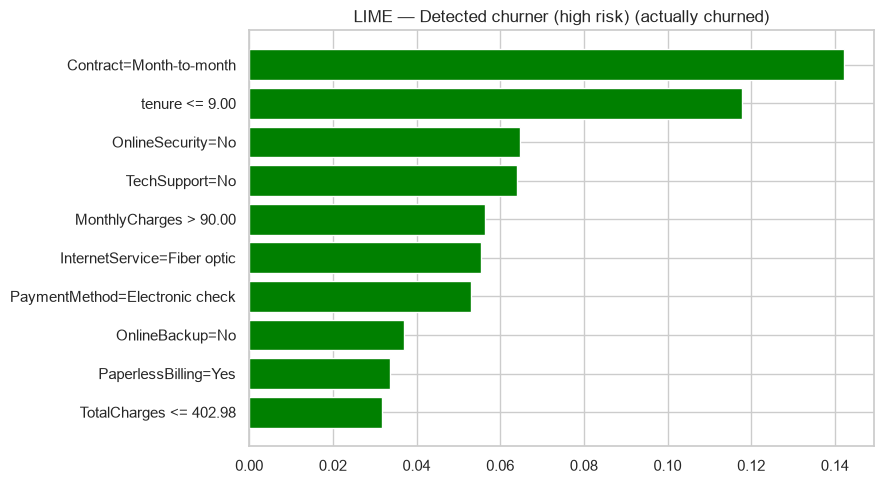

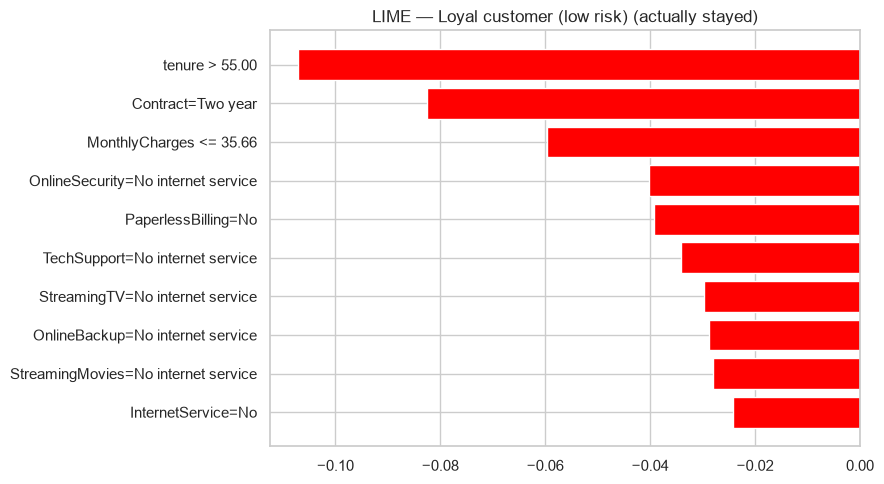

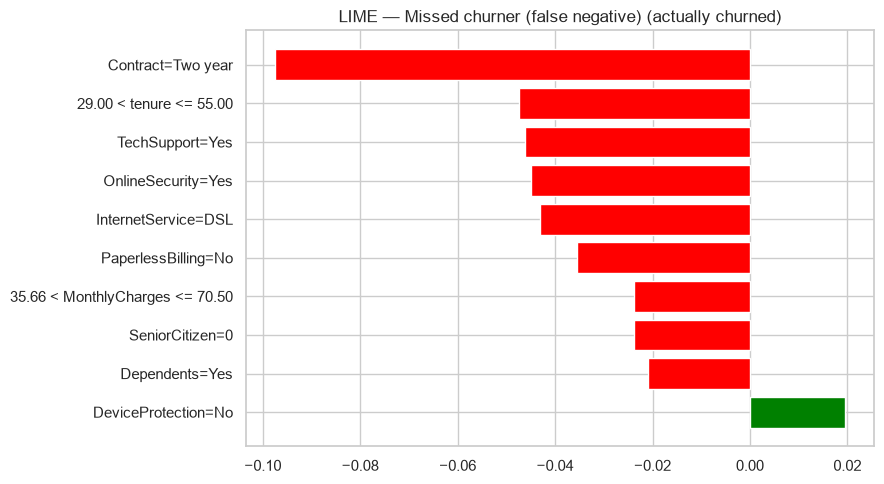

In [48]:
for customer_label, lime_explanation in lime_explanations.items():
    figure = lime_explanation.as_pyplot_figure(label=1)
    figure.set_size_inches(9, 5)
    actual_label = "churned" if target_test.loc[selected_customers[customer_label]] == 1 else "stayed"
    plt.title(f"LIME — {customer_label} (actually {actual_label})", fontsize=12)
    plt.tight_layout()
    plt.show()

### 5.3 SHAP vs LIME vs Random Forest feature importance

**Same customers, two methods.** For each customer, the top 5 variables by absolute contribution are compared,
together with the direction (sign) of each contribution.

In [49]:
def original_variable_of_lime_condition(condition):
    if "=" in condition and not any(operator in condition for operator in ["<=", ">="]):
        return condition.split("=")[0].strip()
    return next(column for column in numeric_features if column in condition)

local_comparison_rows = []
for customer_label, customer_index in selected_customers.items():
    shap_contributions = original_shap_values.loc[customer_index]
    shap_top_variables = shap_contributions.abs().sort_values(ascending=False).head(5).index.tolist()

    lime_contributions = pd.Series({original_variable_of_lime_condition(condition): weight
                                    for condition, weight in lime_explanations[customer_label].as_list(label=1)})
    lime_top_variables = lime_contributions.abs().sort_values(ascending=False).head(5).index.tolist()

    shared_variables = [variable for variable in shap_top_variables if variable in lime_top_variables]
    same_direction = [variable for variable in shared_variables
                      if np.sign(shap_contributions[variable]) == np.sign(lime_contributions[variable])]
    local_comparison_rows.append({
        "customer": customer_label,
        "SHAP top 5": ", ".join(shap_top_variables),
        "LIME top 5": ", ".join(lime_top_variables),
        "shared in top 5": len(shared_variables),
        "shared with same direction": len(same_direction),
    })

pd.DataFrame(local_comparison_rows).set_index("customer")

,SHAP top 5,LIME top 5,shared in top 5,shared with same direction
customer,,,,
Detected churner (high risk),"tenure, Contract, MonthlyCharges, TotalCharges...","Contract, tenure, OnlineSecurity, TechSupport,...",3,3
Loyal customer (low risk),"Contract, tenure, OnlineSecurity, MonthlyCharg...","tenure, Contract, MonthlyCharges, OnlineSecuri...",4,4
Missed churner (false negative),"Contract, tenure, OnlineSecurity, InternetServ...","Contract, tenure, TechSupport, OnlineSecurity,...",5,5


**Global comparison with Random Forest.** The task asks to compare with the Random Forest *feature importance*.
The Random Forest from section 1.9 is trained on the whole training set, and its impurity-based importance
(*Mean Decrease in Impurity*: how much each feature reduces the Gini impurity across all splits of all trees) is summed
over the one-hot columns of each original variable. Both rankings are normalized to sum 1 so they can be compared.

Note the difference in nature: SHAP measures how much each variable moves **the SVM's** predictions, while MDI measures
how useful each variable is **inside the Random Forest's** splits. MDI is also known to favor continuous variables with
many distinct values (such as `MonthlyCharges` and `TotalCharges`).

,SHAP (SVM),Random Forest MDI,SHAP rank,RF rank
Contract,0.224,0.130,1,4
tenure,0.191,0.131,2,3
MonthlyCharges,0.102,0.132,3,2
OnlineSecurity,0.098,0.051,4,6
TechSupport,0.086,0.050,5,7
InternetService,0.078,0.042,6,8
TotalCharges,0.049,0.153,7,1
PaymentMethod,0.047,0.064,8,5
OnlineBackup,0.036,0.033,9,9
PaperlessBilling,0.029,0.023,10,15


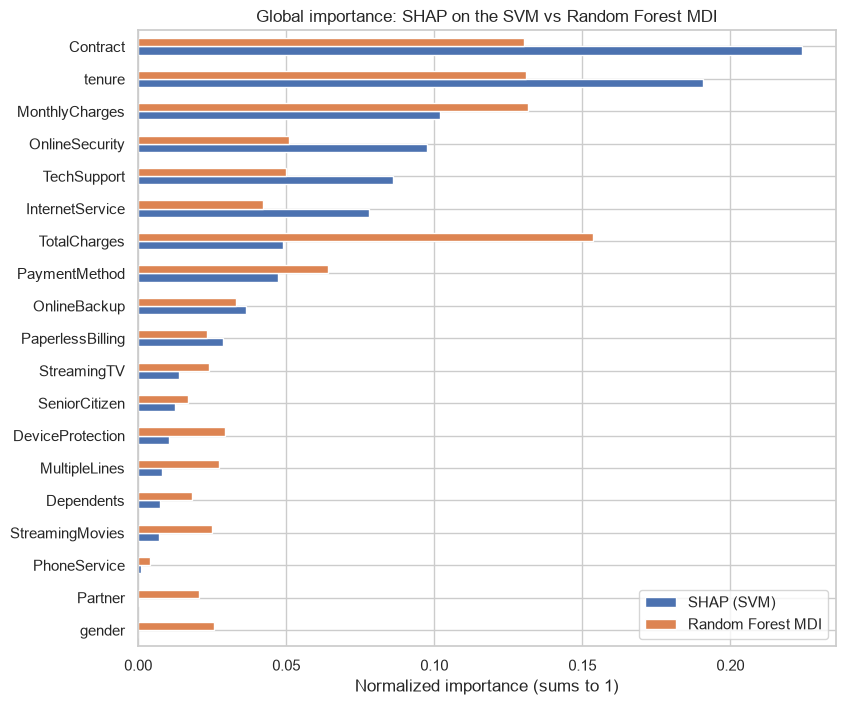

In [50]:
random_forest_pipeline = build_pipeline(candidate_models["Random Forest"]).fit(features_train, target_train)
random_forest_importance = (pd.Series(random_forest_pipeline.named_steps["model"].feature_importances_,
                                      index=transformed_feature_names)
                            .groupby(transformed_to_original).sum())

importance_comparison = pd.DataFrame({
    "SHAP (SVM)": global_shap_importance / global_shap_importance.sum(),
    "Random Forest MDI": random_forest_importance / random_forest_importance.sum(),
}).sort_values("SHAP (SVM)", ascending=False)
importance_comparison["SHAP rank"] = importance_comparison["SHAP (SVM)"].rank(ascending=False).astype(int)
importance_comparison["RF rank"] = importance_comparison["Random Forest MDI"].rank(ascending=False).astype(int)
display(importance_comparison.round(3))

axis = importance_comparison[["SHAP (SVM)", "Random Forest MDI"]].iloc[::-1].plot.barh(figsize=(9, 8))
axis.set_xlabel("Normalized importance (sums to 1)")
axis.set_title("Global importance: SHAP on the SVM vs Random Forest MDI")
plt.show()

#### Comparative analysis

**1. Similarities and differences between SHAP and LIME.**
For the three customers, both methods tell the same story: 3 to 4 of the top-5 variables are shared, and every shared
variable pushes in the **same direction** (table above). For the detected churner both point to the month-to-month
contract, the very short tenure, the lack of online security and technical support, and the high monthly charge.
Two methods built on completely different ideas (fair game-theoretic attribution vs a local linear imitation) agreeing
on the drivers is strong evidence that the explanations reflect the model's real behavior.

The differences are in the details:
- **Additivity.** SHAP contributions add up exactly to the SVM's probability. LIME's local linear model only
  approximates it: it predicts 0.586 for the detected churner (SVM: 0.813) and even a negative value for the loyal
  customer, which is not a valid probability. LIME captures the **direction and ranking** of the effects, not their exact size.
- **Form of the explanation.** SHAP explains the customer's exact values (`tenure = 1`); LIME explains ranges
  learned from training quartiles (`tenure <= 9`).
- **Scope and stability.** SHAP can be aggregated into a global importance; LIME is local only, and its result depends
  on the random neighbors and on the kernel width.

**2. Most relevant variables.** Globally, `Contract` and `tenure` dominate, followed by `MonthlyCharges`,
`OnlineSecurity`, `TechSupport` and `InternetService`. Locally, the same variables appear at the top of both
SHAP and LIME. Demographic variables (`gender`, `Partner`, `Dependents`) are practically irrelevant.
This matches the bivariate analysis: low commitment (short tenure, month-to-month contract), high price and the
absence of support services are associated with churn.

**3. Explaining a prediction to a non-technical person.** Avoid probabilities, coefficients and feature names; use
the customer's own situation and a concrete action:

> *"This customer has a high risk of leaving (about 8 in 10). The main reasons are that they joined only a month ago,
> they have no contract that ties them to us, and they pay one of our highest monthly fees without technical support.
> Customers like this usually decide in their first months. We suggest calling them this week with an annual contract
> offer that includes technical support."*

And for the missed churner: *"The model saw a loyal customer: many years with us, a two-year contract and support
services. Whatever made them leave is not in our data, so no model trained on this data could have warned us."*

**4. Limitations of both techniques.**
- **Association, not causation.** Both explain what the model has learned to associate with churn, not what causes it.
  Changing a customer's contract will not necessarily change their decision.
- **They explain the model, not reality.** If the model is wrong (as with the false negative), the explanation
  faithfully describes a wrong reasoning.
- **Unrealistic synthetic data.** Both create artificial combinations (SHAP when "removing" variables, LIME when
  perturbing), such as a customer with long tenure but a tiny `TotalCharges`, which never occur in reality.
- **SHAP:** `KernelExplainer` is slow for an SVM, so it was computed on a sample of 150 test customers and depends on
  the chosen background (10 k-means centers).

**5. Comparison with Random Forest feature importance.**
- **Agreement:** `Contract`, `tenure` and `MonthlyCharges` are in the top 4 of both rankings.
- **Disagreement:** `TotalCharges` is 1st for the Random Forest but 7th for SHAP, and `gender` gets some importance in
  the Random Forest but zero in SHAP.
- **Reason:** Random Forest importance (MDI) is biased towards continuous variables with many distinct values, because
  they offer more split points.
- **Conclusion:** SHAP is the more reliable reference, since it explains the selected SVM directly.

**Most important features overall:** `Contract`, `tenure` and `MonthlyCharges`, followed by the support services
(`OnlineSecurity`, `TechSupport`) and the internet type (`InternetService`).

## Part 6. Business view and model export

### 6.1 Business figures (test set)

These figures translate the final model's test results into the language of a sales or retention manager.
They use the **test set** (1,409 customers the model never saw) and are exported to `figures/` for the presentation.

**Hypothetical assumptions** (declared, not data) used only in figure B4:

| Assumption | Value | Justification |
|---|---|---|
| Cost of one retention contact | $10 | A call by the retention team plus a small incentive. |
| Retention success rate | 30% | Share of contacted real churners who stay thanks to the action. |
| Value of a retained customer | 12 × `MonthlyCharges` | One year of the customer's own monthly revenue (real data). |

In [51]:
HYPOTHETICAL_RETENTION_SUCCESS_RATE = 0.30
RETAINED_MONTHS_OF_REVENUE = 12

business_test_table = (features_test[["MonthlyCharges", "tenure", "Contract"]]
                       .assign(actual_churn=target_test.to_numpy(), churn_probability=test_churn_probabilities)
                       .sort_values("churn_probability", ascending=False)
                       .reset_index(names="customer_index"))
business_test_table["share_of_customers_contacted"] = np.arange(1, len(business_test_table) + 1) / len(business_test_table)
business_test_table["share_of_churners_reached"] = business_test_table["actual_churn"].cumsum() / business_test_table["actual_churn"].sum()

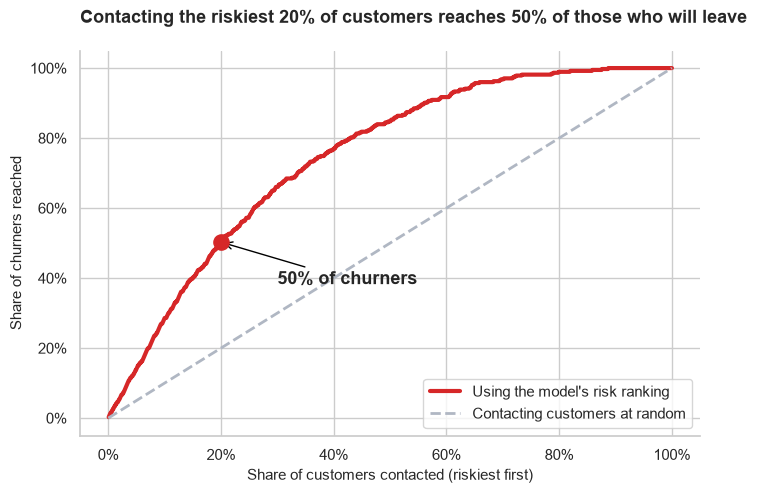

In [52]:
# B1 — Cumulative gains: contacting customers in order of predicted risk
churners_reached_at_20_percent = business_test_table.loc[
    business_test_table["share_of_customers_contacted"] <= 0.20, "share_of_churners_reached"].max()

figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(business_test_table["share_of_customers_contacted"], business_test_table["share_of_churners_reached"],
          color=BUSINESS_HIGHLIGHT_COLOR, linewidth=3, label="Using the model's risk ranking")
axis.plot([0, 1], [0, 1], color=BUSINESS_NEUTRAL_COLOR, linestyle="--", linewidth=2, label="Contacting customers at random")
axis.scatter([0.20], [churners_reached_at_20_percent], color=BUSINESS_HIGHLIGHT_COLOR, s=120, zorder=5)
axis.annotate(f"{churners_reached_at_20_percent:.0%} of churners", (0.20, churners_reached_at_20_percent),
              xytext=(0.30, churners_reached_at_20_percent - 0.12), fontsize=13, fontweight="bold",
              arrowprops={"arrowstyle": "->", "color": "black"})
axis.set_title(f"Contacting the riskiest 20% of customers reaches {churners_reached_at_20_percent:.0%} of those who will leave",
               fontsize=13, fontweight="bold", loc="left", pad=20)
axis.set_xlabel("Share of customers contacted (riskiest first)", fontsize=11)
axis.set_ylabel("Share of churners reached", fontsize=11)
axis.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axis.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axis.spines[["top", "right"]].set_visible(False)
axis.legend(loc="lower right", fontsize=11)
save_business_figure(figure, "B1_cumulative_gains.png")

,customers,actual_churn_rate,monthly_revenue
risk_segment,,,
Low risk\n(< 30%),837,0.099,47849.70
Medium risk\n(30–60%),370,0.392,26106.95
High risk\n(≥ 60%),202,0.723,16344.55


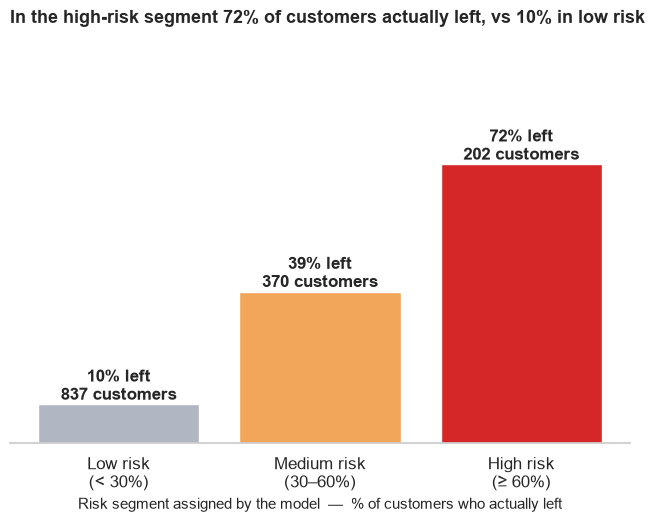

In [53]:
# B5 — Risk segments
RISK_SEGMENT_EDGES = [0, 0.30, 0.60, 1.0]
RISK_SEGMENT_LABELS = ["Low risk\n(< 30%)", "Medium risk\n(30–60%)", "High risk\n(≥ 60%)"]
business_test_table["risk_segment"] = pd.cut(business_test_table["churn_probability"], bins=RISK_SEGMENT_EDGES,
                                             labels=RISK_SEGMENT_LABELS, include_lowest=True)
risk_segment_summary = business_test_table.groupby("risk_segment", observed=False).agg(
    customers=("actual_churn", "size"), actual_churn_rate=("actual_churn", "mean"),
    monthly_revenue=("MonthlyCharges", "sum"))
display(risk_segment_summary.round(3))

figure, axis = plt.subplots(figsize=(8, 5))
bars = axis.bar(risk_segment_summary.index.astype(str), risk_segment_summary["actual_churn_rate"],
                color=[BUSINESS_NEUTRAL_COLOR, "#f2a65a", BUSINESS_HIGHLIGHT_COLOR])
axis.bar_label(bars, labels=[f"{rate:.0%} left\n{count:,} customers" for rate, count in
                             zip(risk_segment_summary["actual_churn_rate"], risk_segment_summary["customers"])],
               fontsize=12, fontweight="bold")
high_risk_churn_rate = risk_segment_summary["actual_churn_rate"].iloc[-1]
low_risk_churn_rate = risk_segment_summary["actual_churn_rate"].iloc[0]
axis.set_title(f"In the high-risk segment {high_risk_churn_rate:.0%} of customers actually left, vs {low_risk_churn_rate:.0%} in low risk",
               fontsize=13, fontweight="bold", loc="left", pad=25)
axis.set_xlabel("Risk segment assigned by the model  —  % of customers who actually left", fontsize=11)
axis.tick_params(axis="x", labelsize=12)
axis.set_ylim(0, 1)
style_business_axis(axis)
save_business_figure(figure, "B5_risk_segments.png")

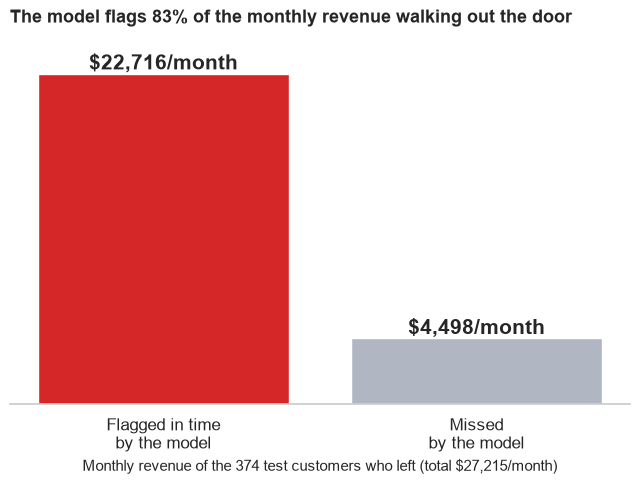

In [54]:
# B3 — Monthly revenue at risk: churners' revenue flagged in time vs missed
test_predicted_labels = pd.Series(test_predictions, index=features_test.index)
churner_mask = target_test == 1
revenue_flagged_in_time = features_test.loc[churner_mask & (test_predicted_labels == 1), "MonthlyCharges"].sum()
revenue_missed = features_test.loc[churner_mask & (test_predicted_labels == 0), "MonthlyCharges"].sum()
total_churner_revenue = revenue_flagged_in_time + revenue_missed

figure, axis = plt.subplots(figsize=(8, 4.5))
bars = axis.bar(["Flagged in time\nby the model", "Missed\nby the model"], [revenue_flagged_in_time, revenue_missed],
                color=[BUSINESS_HIGHLIGHT_COLOR, BUSINESS_NEUTRAL_COLOR])
axis.bar_label(bars, labels=[f"${value:,.0f}/month" for value in [revenue_flagged_in_time, revenue_missed]],
               fontsize=15, fontweight="bold")
axis.set_title(f"The model flags {revenue_flagged_in_time / total_churner_revenue:.0%} of the monthly revenue walking out the door",
               fontsize=13, fontweight="bold", loc="left", pad=25)
axis.set_xlabel(f"Monthly revenue of the {churner_mask.sum()} test customers who left (total ${total_churner_revenue:,.0f}/month)", fontsize=11)
axis.tick_params(axis="x", labelsize=12)
style_business_axis(axis)
save_business_figure(figure, "B3_revenue_at_risk.png")

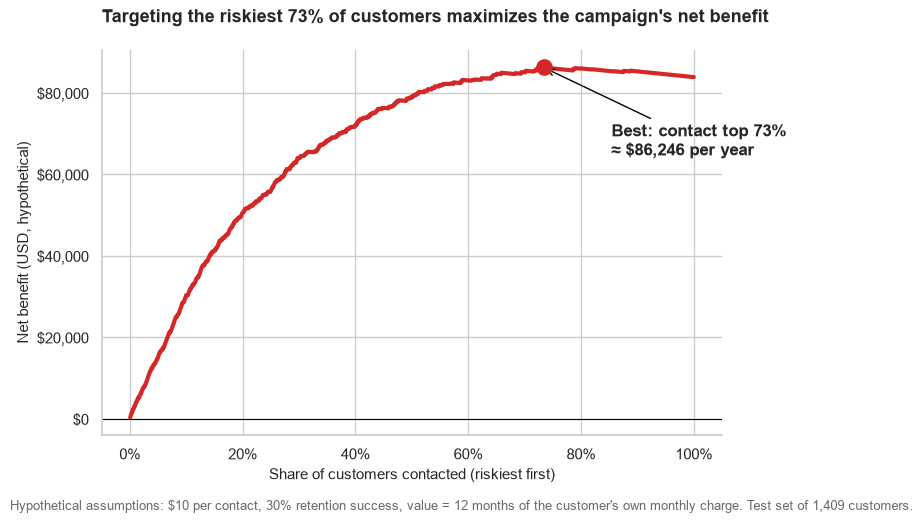

Net benefit contacting everyone: $83,884  |  at the optimum: $86,246


In [55]:
# B4 — Net benefit of a retention campaign depending on how many customers are contacted (hypothetical)
expected_value_per_contact = (business_test_table["actual_churn"] * HYPOTHETICAL_RETENTION_SUCCESS_RATE
                              * business_test_table["MonthlyCharges"] * RETAINED_MONTHS_OF_REVENUE
                              - HYPOTHETICAL_COST_PER_CONTACT)
business_test_table["cumulative_net_benefit"] = expected_value_per_contact.cumsum()
optimal_row = business_test_table.loc[business_test_table["cumulative_net_benefit"].idxmax()]
contact_everyone_benefit = business_test_table["cumulative_net_benefit"].iloc[-1]

figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(business_test_table["share_of_customers_contacted"], business_test_table["cumulative_net_benefit"],
          color=BUSINESS_HIGHLIGHT_COLOR, linewidth=3)
axis.scatter([optimal_row["share_of_customers_contacted"]], [optimal_row["cumulative_net_benefit"]],
             color=BUSINESS_HIGHLIGHT_COLOR, s=120, zorder=5)
axis.annotate(f"Best: contact top {optimal_row['share_of_customers_contacted']:.0%}\n≈ ${optimal_row['cumulative_net_benefit']:,.0f} per year",
              (optimal_row["share_of_customers_contacted"], optimal_row["cumulative_net_benefit"]),
              xytext=(optimal_row["share_of_customers_contacted"] + 0.12, optimal_row["cumulative_net_benefit"] * 0.75),
              fontsize=12, fontweight="bold", arrowprops={"arrowstyle": "->", "color": "black"})
axis.axhline(0, color="black", linewidth=0.8)
axis.set_title(f"Targeting the riskiest {optimal_row['share_of_customers_contacted']:.0%} of customers maximizes the campaign's net benefit",
               fontsize=13, fontweight="bold", loc="left", pad=20)
axis.set_xlabel("Share of customers contacted (riskiest first)", fontsize=11)
axis.set_ylabel("Net benefit (USD, hypothetical)", fontsize=11)
axis.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axis.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("${x:,.0f}"))
axis.spines[["top", "right"]].set_visible(False)
figure.text(0.01, -0.04, f"Hypothetical assumptions: ${HYPOTHETICAL_COST_PER_CONTACT} per contact, "
            f"{HYPOTHETICAL_RETENTION_SUCCESS_RATE:.0%} retention success, value = {RETAINED_MONTHS_OF_REVENUE} months of the "
            f"customer's own monthly charge. Test set of {len(business_test_table):,} customers.", fontsize=9, color="dimgray")
save_business_figure(figure, "B4_campaign_net_benefit.png")
print(f"Net benefit contacting everyone: ${contact_everyone_benefit:,.0f}  |  at the optimum: ${optimal_row['cumulative_net_benefit']:,.0f}")

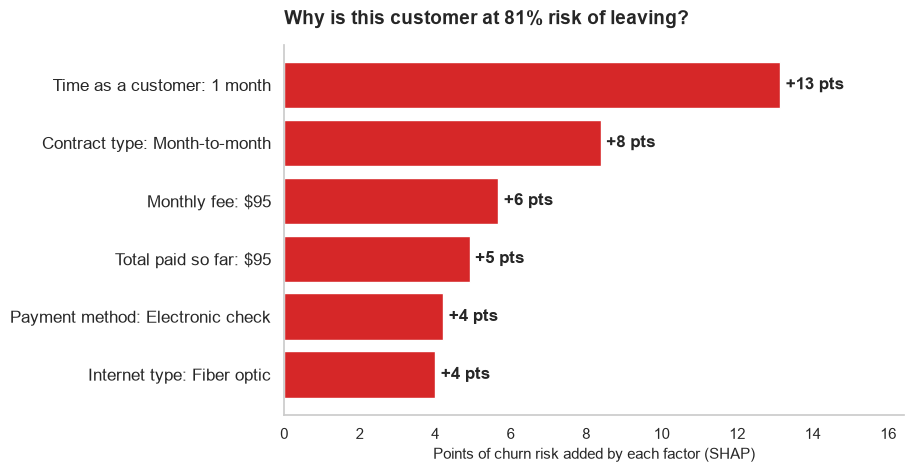

In [56]:
# B7 — Plain-language explanation of one high-risk customer (SHAP values of the detected churner)
plain_language_labels = {
    "tenure": "Time as a customer", "Contract": "Contract type", "MonthlyCharges": "Monthly fee",
    "TotalCharges": "Total paid so far", "PaymentMethod": "Payment method", "OnlineSecurity": "Online security service",
    "TechSupport": "Technical support service", "InternetService": "Internet type", "SeniorCitizen": "Senior citizen",
    "PaperlessBilling": "Paperless billing", "OnlineBackup": "Online backup service",
}
detected_churner_index = selected_customers["Detected churner (high risk)"]
detected_churner_values = features_test.loc[detected_churner_index]
top_risk_drivers = original_shap_values.loc[detected_churner_index].sort_values(key=abs, ascending=False).head(6)[::-1]

def describe_customer_value(variable):
    value = detected_churner_values[variable]
    if variable == "tenure":
        return f"{value} month" + ("" if value == 1 else "s")
    if variable in ["MonthlyCharges", "TotalCharges"]:
        return f"${value:,.0f}"
    if variable == "SeniorCitizen":
        return "Yes" if value == 1 else "No"
    return str(value)

driver_labels = [f"{plain_language_labels.get(variable, variable)}: {describe_customer_value(variable)}" for variable in top_risk_drivers.index]
detected_churner_probability = test_churn_probabilities[features_test.index.get_loc(detected_churner_index)]

figure, axis = plt.subplots(figsize=(8, 4.8))
bars = axis.barh(driver_labels, top_risk_drivers.values * 100,
                 color=[BUSINESS_HIGHLIGHT_COLOR if value > 0 else "#1f77b4" for value in top_risk_drivers.values])
axis.bar_label(bars, labels=[f"+{value * 100:.0f} pts" if value > 0 else f"{value * 100:.0f} pts" for value in top_risk_drivers.values],
               fontsize=12, fontweight="bold", padding=4)
axis.set_title(f"Why is this customer at {detected_churner_probability:.0%} risk of leaving?",
               fontsize=14, fontweight="bold", loc="left", pad=15)
axis.set_xlabel("Points of churn risk added by each factor (SHAP)", fontsize=11)
axis.tick_params(axis="y", labelsize=12)
axis.spines[["top", "right"]].set_visible(False)
axis.grid(False)
axis.set_xlim(0, top_risk_drivers.max() * 100 * 1.25)
save_business_figure(figure, "B7_customer_explanation.png")

### 6.2 Exporting the model and results for the Streamlit app

The Streamlit app must **not retrain** anything. Only two files are exported:

| File | Content |
|---|---|
| `final_svm_pipeline.joblib` | The fitted final pipeline (preprocessing + SVM), used for predictions. |
| `app_results.joblib` | Everything the app displays: metadata, model comparison, optimization results, Pareto front, test metrics and predictions, importance comparison, the SHAP background and the training predictors (needed by LIME's sampling, not for retraining). |

In [57]:
import joblib

MODELS_DIRECTORY = Path("models")
MODELS_DIRECTORY.mkdir(exist_ok=True)
for previous_export in MODELS_DIRECTORY.iterdir():
    previous_export.unlink()

joblib.dump(final_pipeline, MODELS_DIRECTORY / "final_svm_pipeline.joblib")

model_metadata = {
    "model": "SVM (RBF kernel), class_weight='balanced', probability=True",
    "hyperparameters": final_hyperparameters,
    "primary_metric": "F2",
    "test_metrics": test_metrics,
    "cross_validation_metrics": cross_validation_metrics,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "category_values": category_values_by_column,
    "shap_base_value": float(shap_explainer.expected_value),
    "hypothetical_assumptions": {"cost_per_contact": HYPOTHETICAL_COST_PER_CONTACT,
                                 "retention_success_rate": HYPOTHETICAL_RETENTION_SUCCESS_RATE,
                                 "retained_months_of_revenue": RETAINED_MONTHS_OF_REVENUE},
    "risk_segment_edges": RISK_SEGMENT_EDGES,
}

app_results = {
    "metadata": model_metadata,
    "model_comparison_cv": comparison_table,
    "business_impact_cv": business_impact_table,
    "optimization_strategies": strategy_comparison,
    "grid_search_f2_matrix": grid_f2_matrix,
    "nsga2_trials": nsga2_trials_table,
    "grid_best_speed": grid_best_row,
    "importance_comparison": importance_comparison,
    "test_confusion_matrix": pd.crosstab(target_test, test_predictions),
    "test_predictions": business_test_table,
    "shap_background": shap_background.data,
    "features_train": features_train,
}
joblib.dump(app_results, MODELS_DIRECTORY / "app_results.joblib")

for exported_file in sorted(MODELS_DIRECTORY.iterdir()):
    print(f"{exported_file.name:35s} {exported_file.stat().st_size / 1024:8.1f} KB")

app_results.joblib                    1517.5 KB
final_svm_pipeline.joblib             1102.0 KB


## Part 7. Conclusions

1. **Data and problem.** Only 26.5% of customers churn, so Accuracy is misleading (73.5% for a model that never
   predicts churn). Churn concentrates in low-commitment customers: month-to-month contracts (43% churn vs 3% for
   two-year contracts) and customers in their first 6 months (52%).

2. **Metric aligned with the business.** A missed churner costs all of their future revenue, while an unnecessary
   contact costs little. F2, which weighs recall twice as much as precision, was therefore chosen as the primary metric
   for model selection and every optimization.

3. **Model selection.** With default hyperparameters, Logistic Regression and the SVM were statistically tied on F2
   and both clearly beat the Random Forest. The SVM was optimized because it trains faster, has a richer hyperparameter
   space and its inference time depends on its hyperparameters.

4. **Hyperparameter optimization.** Grid Search, Random Search and TPE reached the same F2 (≈0.724, +0.013 over the
   default SVM) with the same budget of 36 configurations. The search space has a wide plateau of good solutions,
   and `gamma` is the critical hyperparameter. Grid Search was selected: same result, fastest, and a complete map.

5. **Multi-objective optimization.** NSGA-II showed a real trade-off between F2 and inference time, driven by the number
   of support vectors. The Grid Search winner is not dominated, and the speed gain of faster solutions is negligible at
   this scale, so the highest-F2 model was kept.

6. **Final performance.** On the isolated test set the model reached F2 = 0.714, recall = 0.808 and ROC-AUC = 0.835,
   very close to cross-validation, so it generalizes well. It detects about 8 out of 10 customers who will leave.

7. **Explainability.** SHAP and LIME agree on the main drivers and their direction: contract type, tenure, monthly fee
   and the absence of security and support services. Random Forest importance agrees on the top variables but
   overrates `TotalCharges` because of the bias of impurity-based importance. The explanations turn each prediction
   into a concrete retention action, but they show association, not causation.

8. **Business value.** Ranking customers by risk is far better than random selection: contacting the riskiest 20% reaches
   about half of the churners, and the high-risk segment had a real churn rate of 72% vs 10% in the low-risk segment.
   This is the basis of **Menolyte Core**, a retention platform for mid-sized ISPs.

9. **Limitations and next steps.** The data is a single snapshot from one (fictional) company, so the model must be
   retrained with each client's own data. Its errors concentrate on churners whose reasons are not in the data (the
   false negative explained with SHAP). Economic figures rely on declared hypothetical assumptions, and the proposed
   actions must be validated with A/B tests before scaling.